# Taller · De los datos a un dashboard publicado

**Programación — ADMI 1301**

Trabajarás con las **2.000 ventas de una cadena de papelerías en 2025**. En este taller vas a:

1. **Graficar** (6 ejercicios con `groupby`, `crosstab` y `pivot_table`).
2. **Organizar** tus gráficos en una sola figura con `subplots`: tu *dashboard*.
3. **Embellecerlo con prompts**: le pides a Gemini que reescriba el código de tu figura y pegas su respuesta aquí.
4. **Elegir tu versión favorita**, escribir tus conclusiones y **publicar tu notebook en GitHub**.

Las instrucciones completas están en la guía en Word. Aquí encuentras lo esencial de cada ejercicio y una **verificación** (`assert`) para saber si vas bien.

**Escriba los nombres de los integrantes aca.**
______________________________________________________________________  
 1. Juan Esteban Siachoque  


## 0. Preparación
Ejecuta la celda y sube el archivo **`ventas_papelerias_2025.csv`**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

subidos = files.upload()   # selecciona ventas_papelerias_2025.csv

df = pd.read_csv("ventas_papelerias_2025.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month        # 1 = enero ... 12 = diciembre
df.head()

,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


**Conoce tus datos** antes de graficar: cuántas filas hay, qué columnas, qué valores tiene cada categoría.

In [2]:
print(df.shape)
df.info()
for col in ["ciudad", "canal", "segmento", "categoria", "metodo_pago"]:
    print(col, "->", sorted(df[col].unique()))

(2000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_venta         2000 non-null   str           
 1   fecha            2000 non-null   datetime64[us]
 2   ciudad           2000 non-null   str           
 3   canal            2000 non-null   str           
 4   segmento         2000 non-null   str           
 5   vendedor         2000 non-null   str           
 6   producto         2000 non-null   str           
 7   categoria        2000 non-null   str           
 8   metodo_pago      2000 non-null   str           
 9   cantidad         2000 non-null   int64         
 10  precio_unitario  2000 non-null   int64         
 11  descuento        2000 non-null   float64       
 12  total            2000 non-null   int64         
 13  mes              2000 non-null   int32         
dtypes: datetime64[us](1), float64(1), int32(

---
# Parte A · Seis gráficos
En cada ejercicio: **(1)** prepara una tabla con `groupby`, `crosstab` o `pivot_table`, **(2)** guárdala en la variable indicada, **(3)** grafícala. Ponle **título** a cada gráfico.

### Ejercicio 1 · Top 5 de productos *(barras horizontales)*
**Contexto.** La gerente de compras debe decidir en qué productos concentrar el inventario del próximo año.

**Tarea.** Calcula los ingresos (`total`) por `producto`, quédate con los **5 mayores** y grafícalos en barras horizontales. Guarda la tabla en **`top_productos`**.

*Herramientas:* `groupby`, `sum`, `sort_values`, `head`, `.plot.barh()`

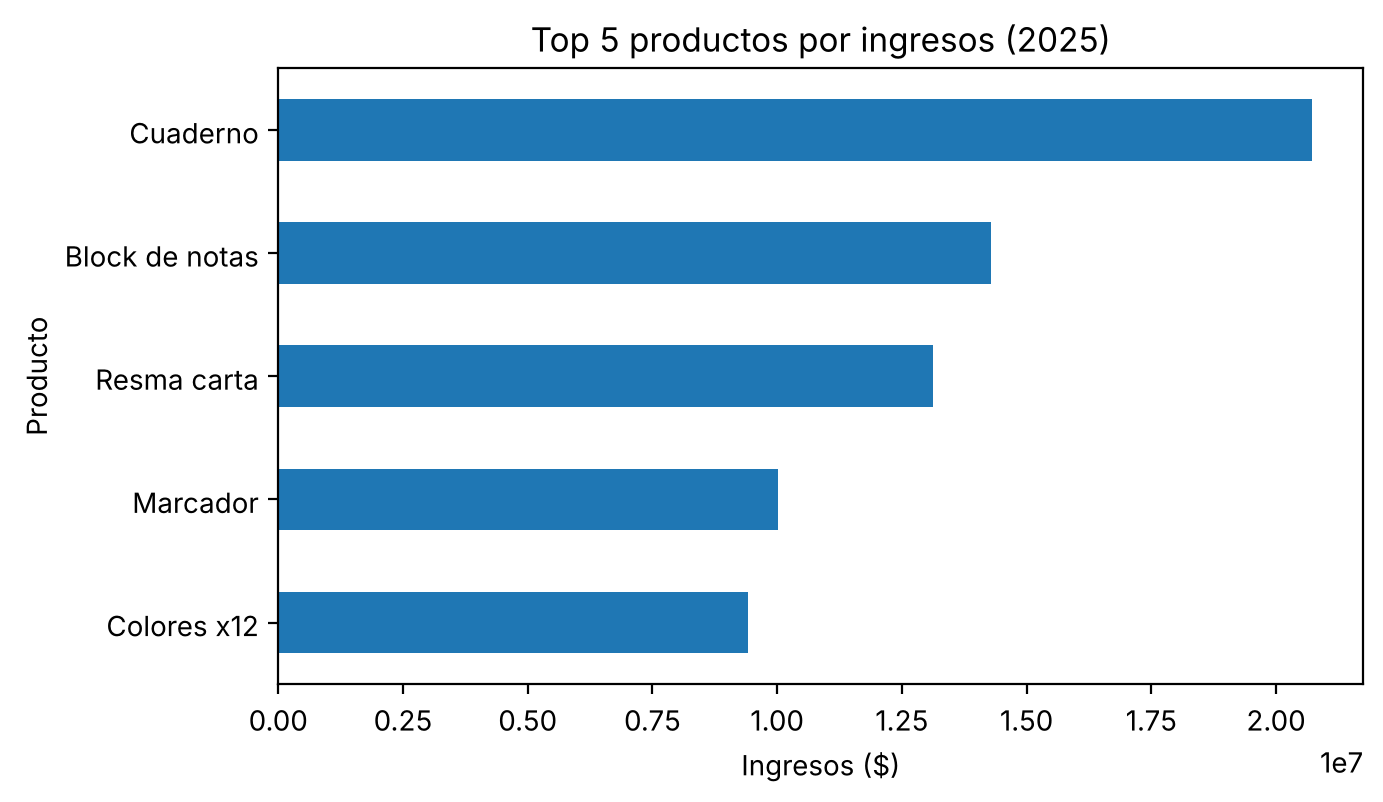

producto
Cuaderno          20712345
Block de notas    14292347
Resma carta       13133570
Marcador          10020786
Colores x12        9419625
Name: total, dtype: int64

In [3]:
# Ejercicio 1 · Top 5 de productos
top_productos = (df.groupby("producto")["total"].sum()
                   .sort_values(ascending=False)
                   .head(5))

top_productos.sort_values().plot.barh(figsize=(7, 4), title="Top 5 productos por ingresos (2025)")
plt.xlabel("Ingresos ($)")
plt.ylabel("Producto")
plt.show()
top_productos

In [4]:
# ✅ Verificación
assert len(top_productos) == 5, "Debe haber exactamente 5 productos"
assert top_productos.index[0] == "Cuaderno", "El producto con más ingresos no coincide: revisa el ordenamiento"
assert abs(top_productos.iloc[0] - 20712345) < 1, "Revisa que estés sumando la columna total"
print("Ejercicio 1 correcto ✔")

Ejercicio 1 correcto ✔


### Ejercicio 2 · Ingresos mes a mes: Bogotá vs Medellín *(líneas)*
**Contexto.** La dirección regional quiere comparar la evolución de sus dos ciudades principales durante el año.

**Tarea.** **Selecciona** solo las ventas de Bogotá y Medellín (`isin`). Con una **tabla dinámica** pon los meses en las filas, las ciudades en las columnas y la suma de `total` como valores. Guárdala en **`ing_mes_ciudad`** y grafícala como líneas con marcadores.

*Herramientas:* filtrado con `isin`, `pivot_table`, `.plot.line(marker="o")`

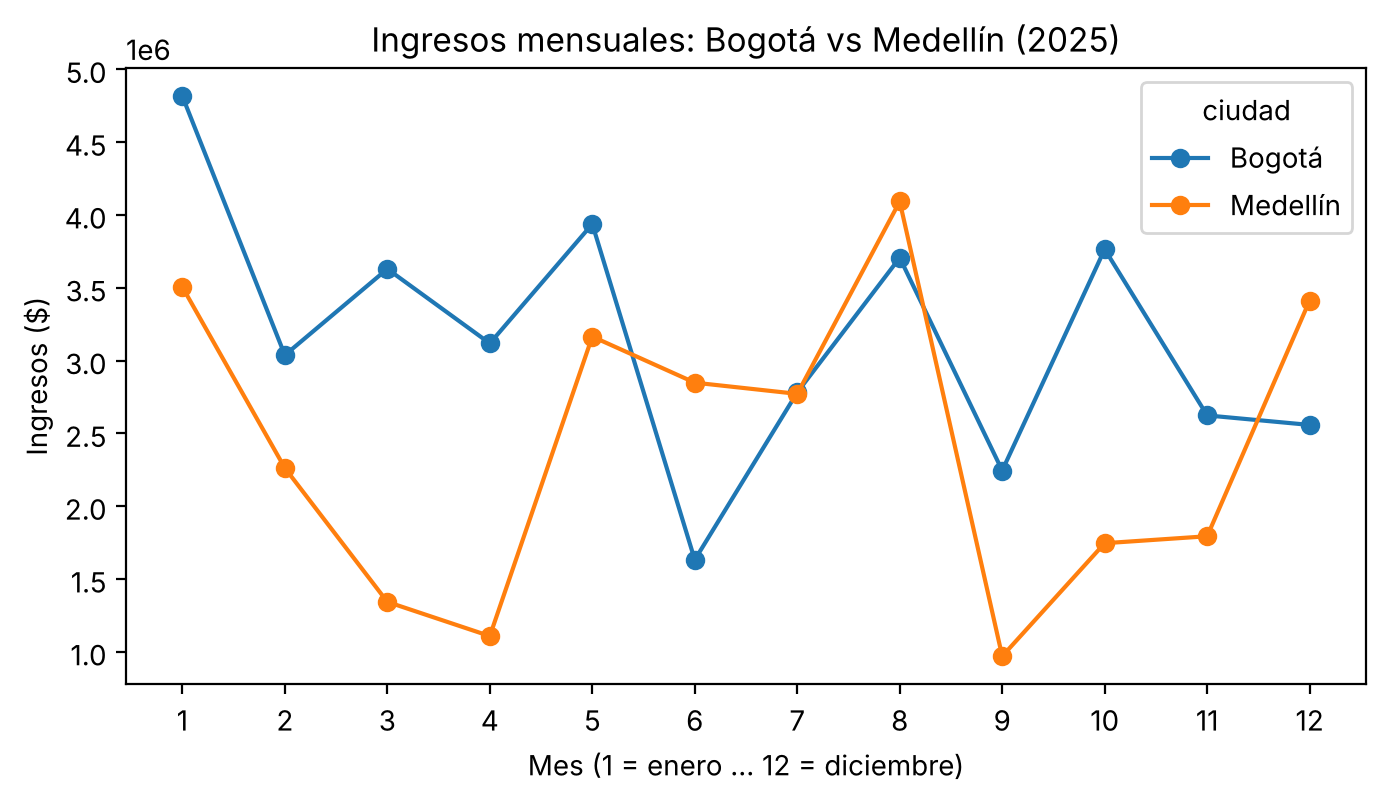

ciudad,Bogotá,Medellín
mes,,
1,4815405,3504905
2,3037200,2262080
3,3629385,1342665
4,3117990,1107910
5,3937775,3164730
6,1631810,2848235
7,2781218,2771377
8,3706217,4092446
9,2245001,969551


In [5]:
# Ejercicio 2 · Bogotá vs Medellín mes a mes
dos_ciudades = df[df["ciudad"].isin(["Bogotá", "Medellín"])]

ing_mes_ciudad = dos_ciudades.pivot_table(index="mes", columns="ciudad",
                                          values="total", aggfunc="sum")

ing_mes_ciudad.plot.line(marker="o", figsize=(8, 4), title="Ingresos mensuales: Bogotá vs Medellín (2025)")
plt.xlabel("Mes (1 = enero ... 12 = diciembre)")
plt.ylabel("Ingresos ($)")
plt.xticks(range(1, 13))
plt.show()
ing_mes_ciudad

In [6]:
# ✅ Verificación
assert ing_mes_ciudad.shape == (12, 2), f"Se esperaba una tabla de 12 meses x 2 ciudades, tienes {ing_mes_ciudad.shape}"
assert set(ing_mes_ciudad.columns) == {"Bogotá", "Medellín"}, "Las columnas deben ser las dos ciudades"
assert abs(ing_mes_ciudad["Bogotá"].sum() - 37847614) < 1, "El total de Bogotá no coincide"
print("Ejercicio 2 correcto ✔")

Ejercicio 2 correcto ✔


### Ejercicio 3 · ¿Por qué canal se vende más? *(gráfico de pie)*
**Contexto.** La empresa evalúa si invierte más en su tienda online o en la atención telefónica.

**Tarea.** Calcula los ingresos totales por `canal`, guárdalos en **`ing_canal`** y grafica la participación de cada canal con un gráfico de pie que muestre los **porcentajes con un decimal**.

*Herramientas:* `groupby`, `.plot.pie(autopct=...)`

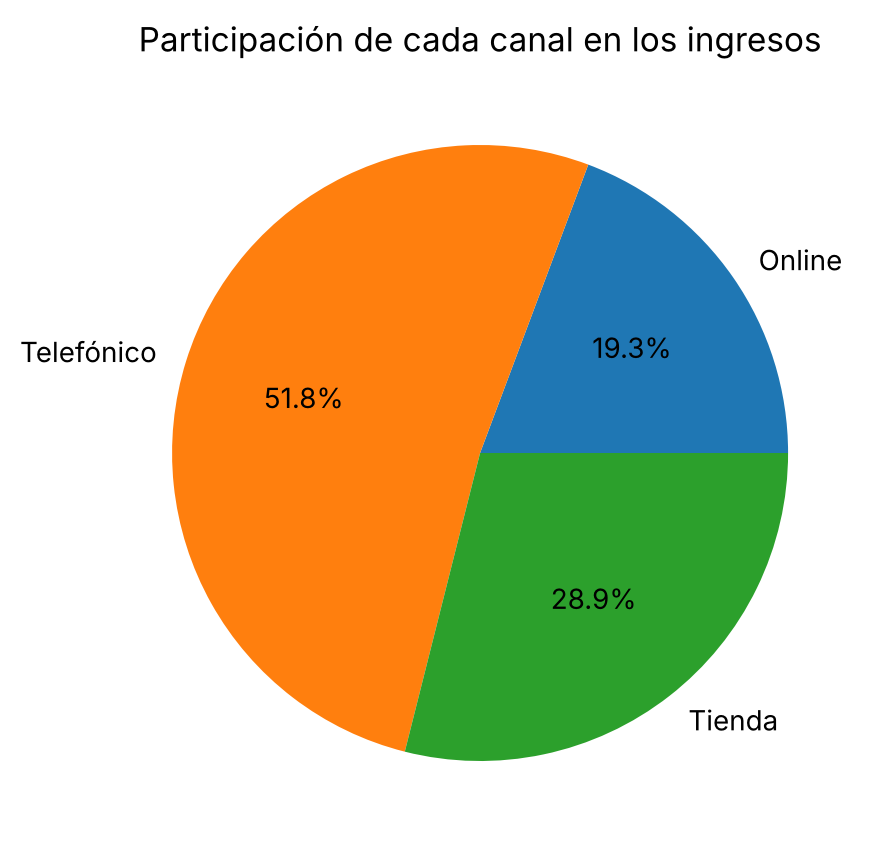

canal
Online        22887574
Telefónico    61450716
Tienda        34329722
Name: total, dtype: int64

In [7]:
# Ejercicio 3 · Participación por canal
ing_canal = df.groupby("canal")["total"].sum()

ing_canal.plot.pie(autopct="%.1f%%", figsize=(5, 5), title="Participación de cada canal en los ingresos")
plt.ylabel("")
plt.show()
ing_canal

In [8]:
# ✅ Verificación
assert abs(ing_canal.sum() - 118668012) < 1, "La suma de los canales debe ser el ingreso total"
assert abs(ing_canal["Telefónico"] / ing_canal.sum() - 0.520) < 0.01, "La participación del canal Telefónico no coincide"
print("Ejercicio 3 correcto ✔")

Ejercicio 3 correcto ✔


### Ejercicio 4 · ¿Cada segmento compra lo mismo? *(barras apiladas)*
**Contexto.** El área comercial sospecha que los clientes corporativos compran productos distintos a los minoristas.

**Tarea.** Con `pd.crosstab` cuenta las ventas por `segmento` (filas) y `categoria` (columnas), **normalizadas por fila** y expresadas en **porcentaje** (de 0 a 100). Guarda la tabla en **`tabla_seg_cat`** y grafícala en barras **apiladas**.

*Herramientas:* `pd.crosstab(..., normalize="index")`, `.plot.bar(stacked=True)`

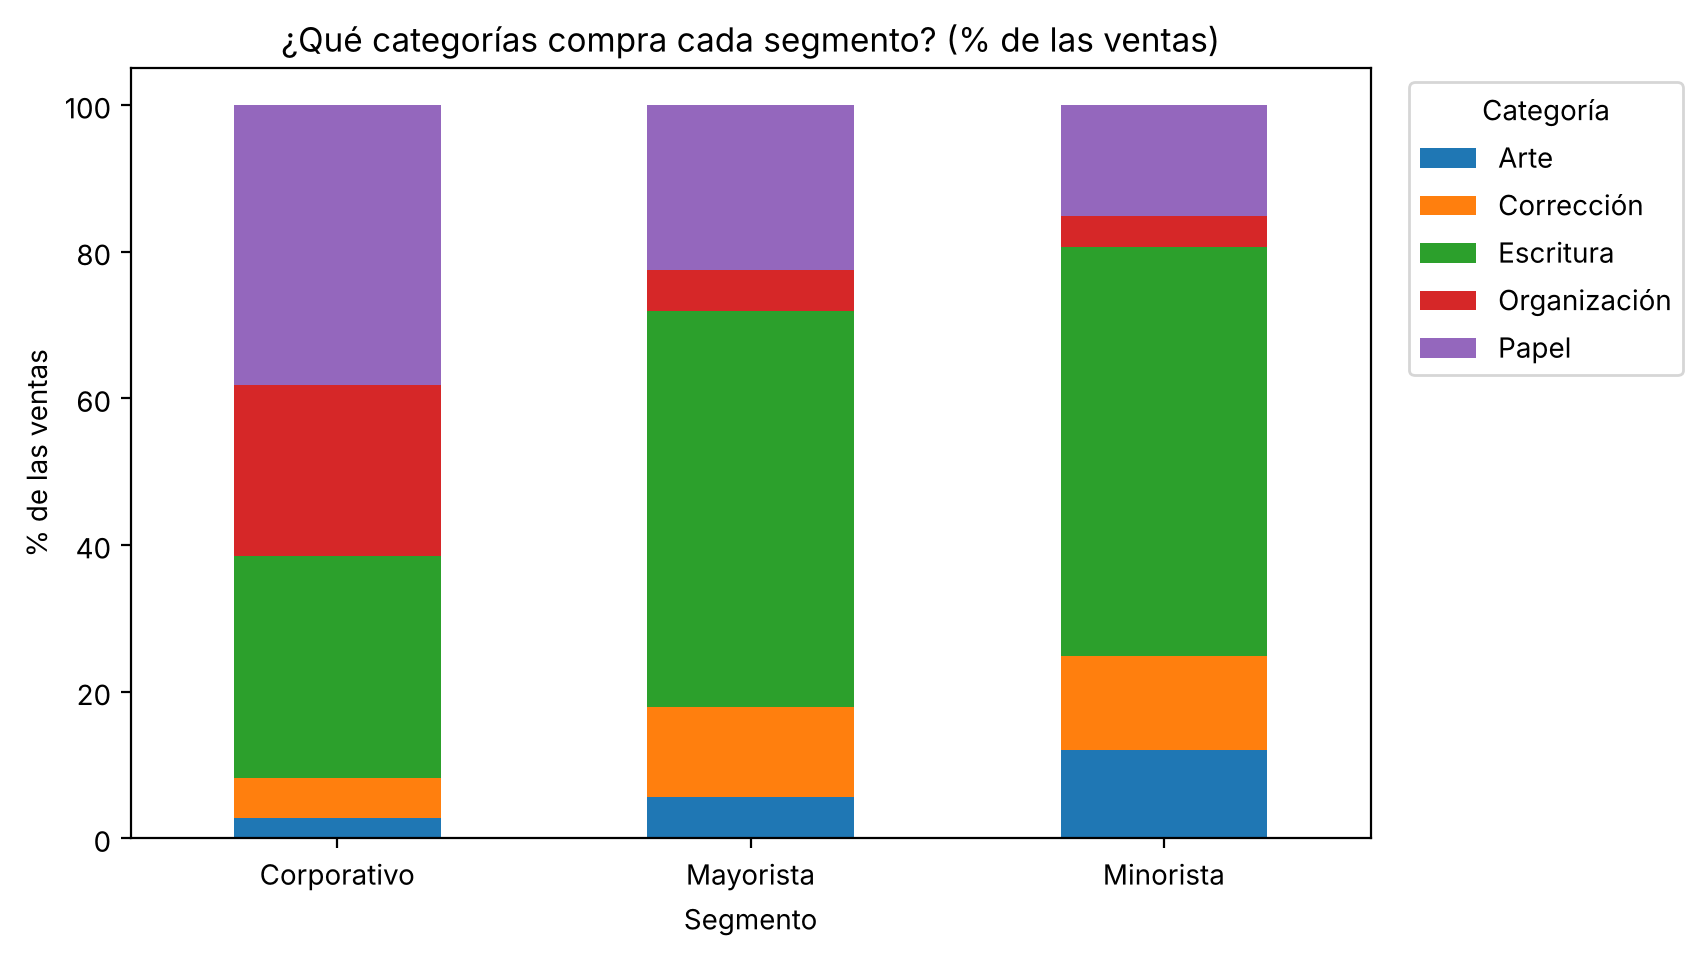

categoria,Arte,Corrección,Escritura,Organización,Papel
segmento,,,,,
Corporativo,2.8,5.4,30.2,23.3,38.2
Mayorista,5.6,12.2,54.0,5.6,22.5
Minorista,12.1,12.8,55.8,4.3,15.2


In [9]:
# Ejercicio 4 · Segmento vs categoría (% por fila)
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100

tabla_seg_cat.plot.bar(stacked=True, figsize=(8, 5), title="¿Qué categorías compra cada segmento? (% de las ventas)")
plt.xlabel("Segmento")
plt.ylabel("% de las ventas")
plt.xticks(rotation=0)
plt.legend(title="Categoría", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()
tabla_seg_cat.round(1)

In [10]:
# ✅ Verificación
assert tabla_seg_cat.shape == (3, 5), f"Se esperaba 3 segmentos x 5 categorías, tienes {tabla_seg_cat.shape}"
assert (abs(tabla_seg_cat.sum(axis=1) - 100) < 0.01).all(), "Cada fila debe sumar 100 (usa normalize y multiplica por 100)"
print("Ejercicio 4 correcto ✔")

Ejercicio 4 correcto ✔


### Ejercicio 5 · Productividad de los vendedores *(dispersión)*
**Contexto.** Recursos humanos revisa qué vendedores concretan más ventas y cuáles venden tickets más altos.

**Tarea.** Con `groupby` por `vendedor` y `ciudad`, calcula para cada vendedor el **número de ventas** (`n_ventas`) y el **valor promedio de sus ventas** (`ticket_prom`). Guarda la tabla en **`vend`** (con índice normal: usa `reset_index()`). Haz una dispersión (`n_ventas` en X, `ticket_prom` en Y) con un **color por ciudad** y leyenda.

*Herramientas:* `groupby().agg(nombre=("columna", "función"))`, `reset_index`, `plt.scatter` dentro de un `for`

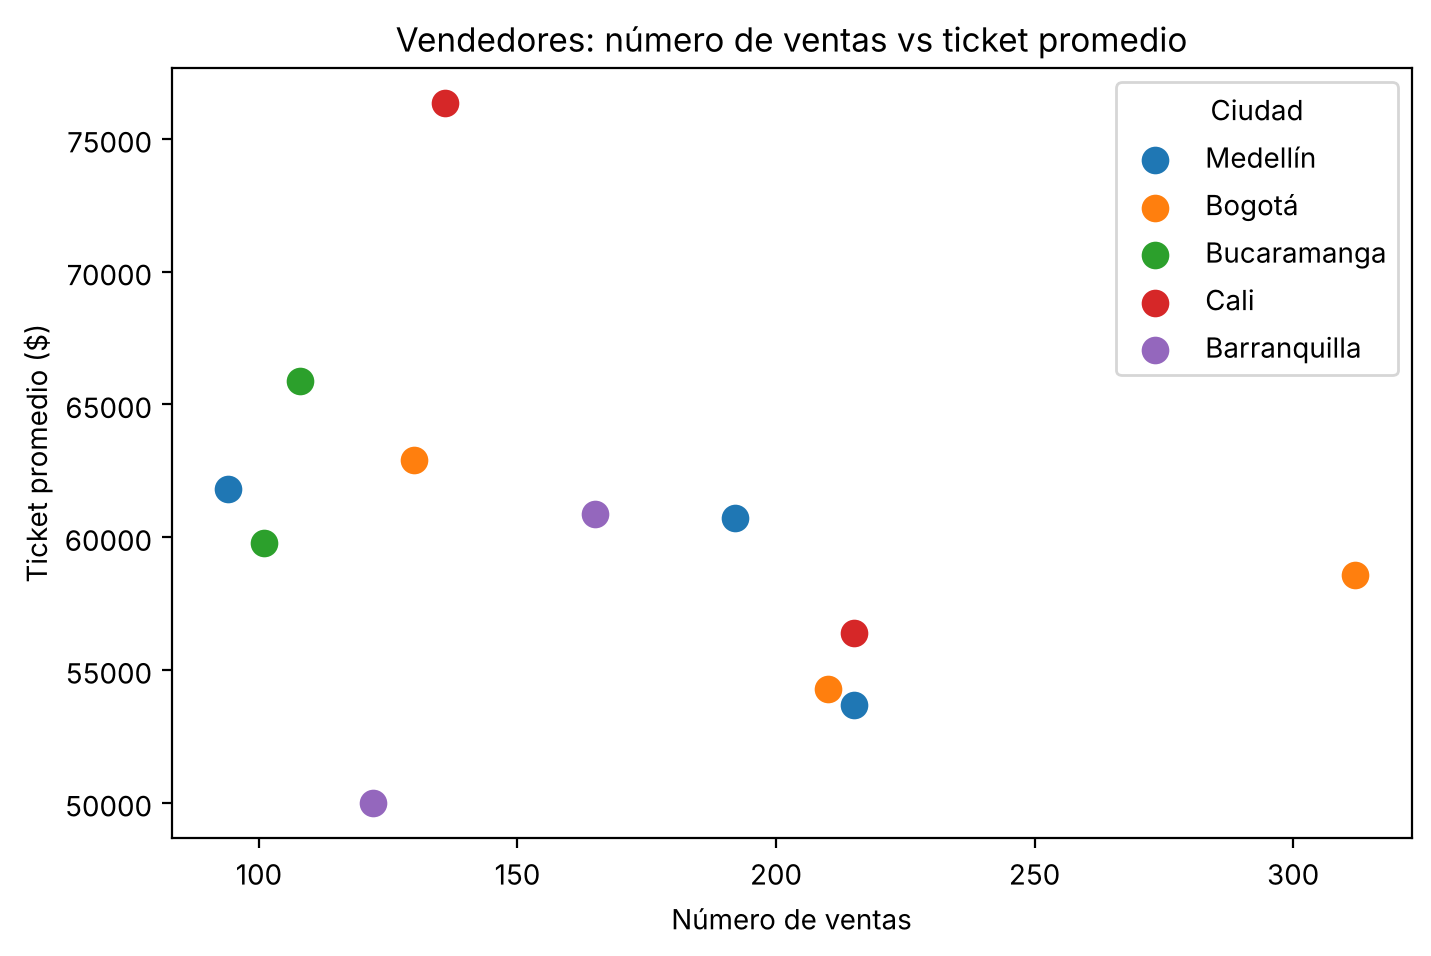

,vendedor,ciudad,n_ventas,ticket_prom
0,Andrés Rojas,Medellín,192,60729.104167
1,Camilo Pardo,Bogotá,210,54276.595238
2,Daniela Ríos,Bogotá,130,62903.423077
3,Esteban Uribe,Medellín,94,61833.978723
4,Isabela Mora,Bucaramanga,108,65873.037037
5,Julián Cortés,Cali,215,56389.920930
6,Laura Gómez,Bogotá,312,58564.371795
7,Mateo Peña,Barranquilla,165,60888.484848
8,Paula Vargas,Cali,136,76343.213235
9,Santiago Duarte,Bucaramanga,101,59798.841584


In [11]:
# Ejercicio 5 · Productividad de los vendedores
vend = (df.groupby(["vendedor", "ciudad"])
          .agg(n_ventas=("total", "size"), ticket_prom=("total", "mean"))
          .reset_index())

plt.figure(figsize=(8, 5))
for ciudad in vend["ciudad"].unique():
    sub = vend[vend["ciudad"] == ciudad]
    plt.scatter(sub["n_ventas"], sub["ticket_prom"], label=ciudad, s=80)
plt.title("Vendedores: número de ventas vs ticket promedio")
plt.xlabel("Número de ventas")
plt.ylabel("Ticket promedio ($)")
plt.legend(title="Ciudad")
plt.show()
vend

In [12]:
# ✅ Verificación
assert vend.shape[0] == 12, f"Debe haber una fila por vendedor (12), tienes {vend.shape[0]}"
assert {"vendedor", "ciudad", "n_ventas", "ticket_prom"} <= set(vend.columns), "Faltan columnas: vendedor, ciudad, n_ventas, ticket_prom"
assert vend["n_ventas"].sum() == 2000, "La suma de n_ventas debe ser 2000"
print("Ejercicio 5 correcto ✔")

Ejercicio 5 correcto ✔


### Ejercicio 6 · ¿Qué tan grandes son las ventas de cada segmento? *(diagrama de cajas)*
**Contexto.** Para planear el segundo semestre, finanzas quiere ver cómo se distribuye el valor de las ventas por tipo de cliente.

**Tarea.** **Selecciona** solo las ventas del **segundo semestre** (`mes` de 7 a 12) y guárdalas en **`sem2`**. Haz un diagrama de cajas del `total` por `segmento`, **sin mostrar los valores atípicos** (`showfliers=False`).

*Herramientas:* filtro con `>=`, `.boxplot(column=..., by=...)`

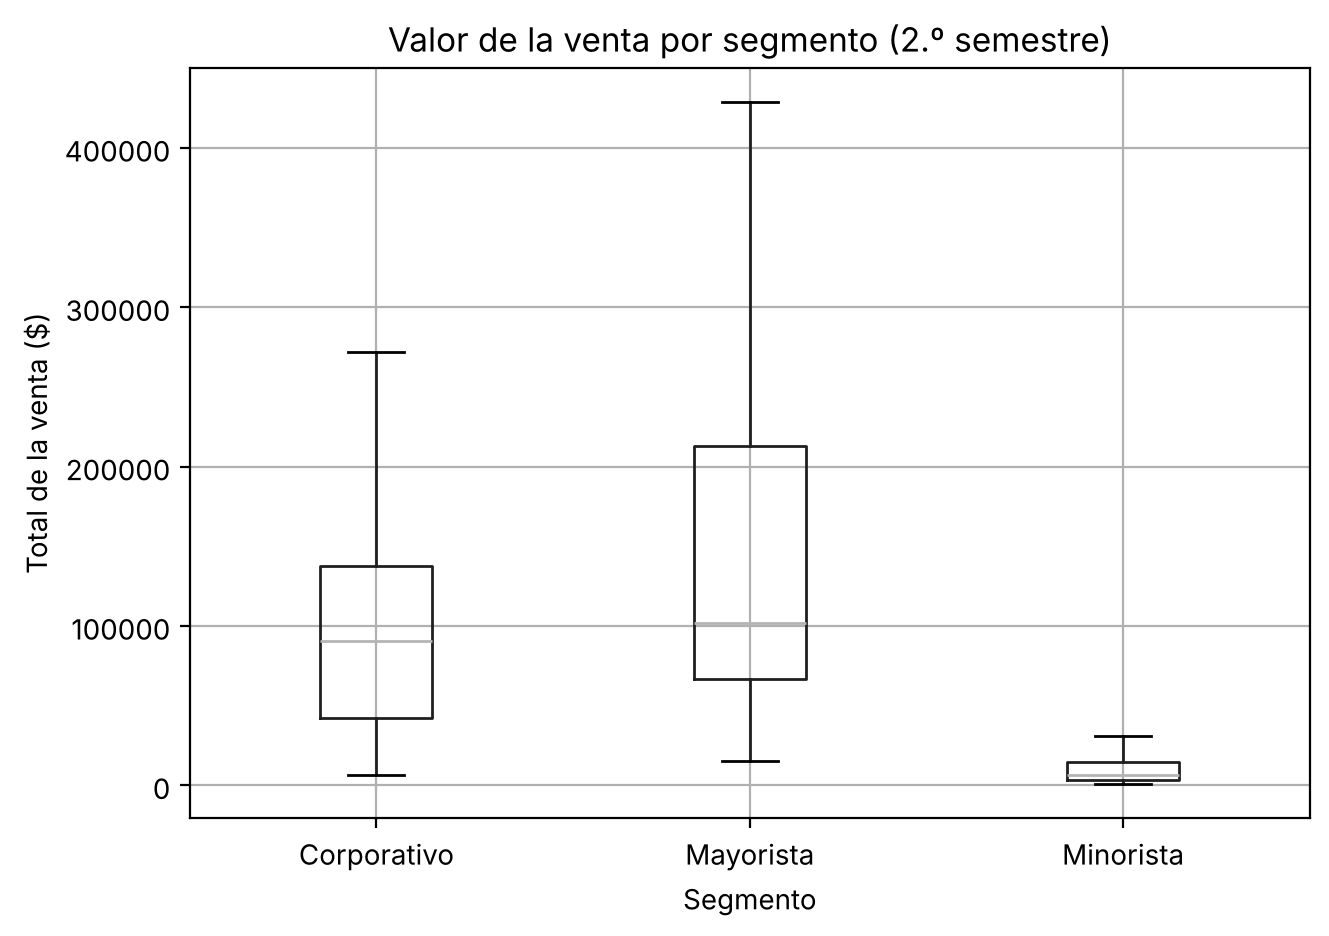

1050

In [13]:
# Ejercicio 6 · Ventas del segundo semestre por segmento
sem2 = df[df["mes"] >= 7]

sem2.boxplot(column="total", by="segmento", showfliers=False, figsize=(7, 5))
plt.title("Valor de la venta por segmento (2.º semestre)")
plt.suptitle("")          # quita el título automático de pandas
plt.xlabel("Segmento")
plt.ylabel("Total de la venta ($)")
plt.show()
len(sem2)

In [14]:
# ✅ Verificación
assert len(sem2) == 1050, f"El segundo semestre debe tener 1050 ventas, tienes {len(sem2)}"
print("Ejercicio 6 correcto ✔")

Ejercicio 6 correcto ✔


---
# Parte B · Todo en una sola figura (`subplots`)
### Ejercicio 7 · Organiza tus 6 gráficos en una cuadrícula de 2 × 3
**Contexto.** La gerente quiere ver todo en **una sola imagen** para presentarla en la junta.

**Tarea.** Crea una figura con `fig, axs = plt.subplots(2, 3, figsize=(18, 10))` y dibuja cada gráfico en su posición pasando **`ax=axs[fila, columna]`**. Agrega un título general con `fig.suptitle(...)` y termina con `plt.tight_layout()`.

**Importante:** escribe el código en la celda que empieza con `%%writefile figura_base.py` (así el programa guarda tu código en un archivo, que usarás en la Parte C). Luego ejecuta la celda siguiente (`%run -i figura_base.py`) para ver la figura.

*Pistas:* `plot.barh(ax=axs[0, 0])` · `plot.pie(...)` también acepta `ax` · para el boxplot: `boxplot(column=..., by=..., ax=...)` · para la dispersión: `axs[1, 1].scatter(...)`

In [15]:
%%writefile figura_base.py
# Ejercicio 7: figura 2x3 con los seis gráficos
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# 1) Top 5 productos (barras horizontales)
top_productos.sort_values().plot.barh(ax=axs[0, 0], title="Top 5 productos por ingresos")
axs[0, 0].set_xlabel("Ingresos ($)")
axs[0, 0].set_ylabel("Producto")

# 2) Ingresos mes a mes: Bogotá vs Medellín (líneas)
ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o", title="Ingresos mensuales: Bogotá vs Medellín")
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos ($)")

# 3) Participación por canal (pie)
ing_canal.plot.pie(ax=axs[0, 2], autopct="%.1f%%", title="Participación de ingresos por canal")
axs[0, 2].set_ylabel("")

# 4) Segmento vs categoría (barras apiladas)
tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True, title="Categorías compradas por segmento (%)")
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("% de las ventas")
axs[1, 0].tick_params(axis="x", rotation=0)

# 5) Productividad de vendedores (dispersión, un color por ciudad)
for ciudad in vend["ciudad"].unique():
    sub = vend[vend["ciudad"] == ciudad]
    axs[1, 1].scatter(sub["n_ventas"], sub["ticket_prom"], label=ciudad, s=80)
axs[1, 1].set_title("Vendedores: número de ventas vs ticket promedio")
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio ($)")
axs[1, 1].legend(title="Ciudad")

# 6) Distribución del total por segmento, 2.º semestre (diagrama de cajas)
sem2.boxplot(column="total", by="segmento", ax=axs[1, 2], showfliers=False)
axs[1, 2].set_title("Valor de la venta por segmento (2.º semestre)")
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Total de la venta ($)")

fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=18)
plt.tight_layout()


Writing figura_base.py


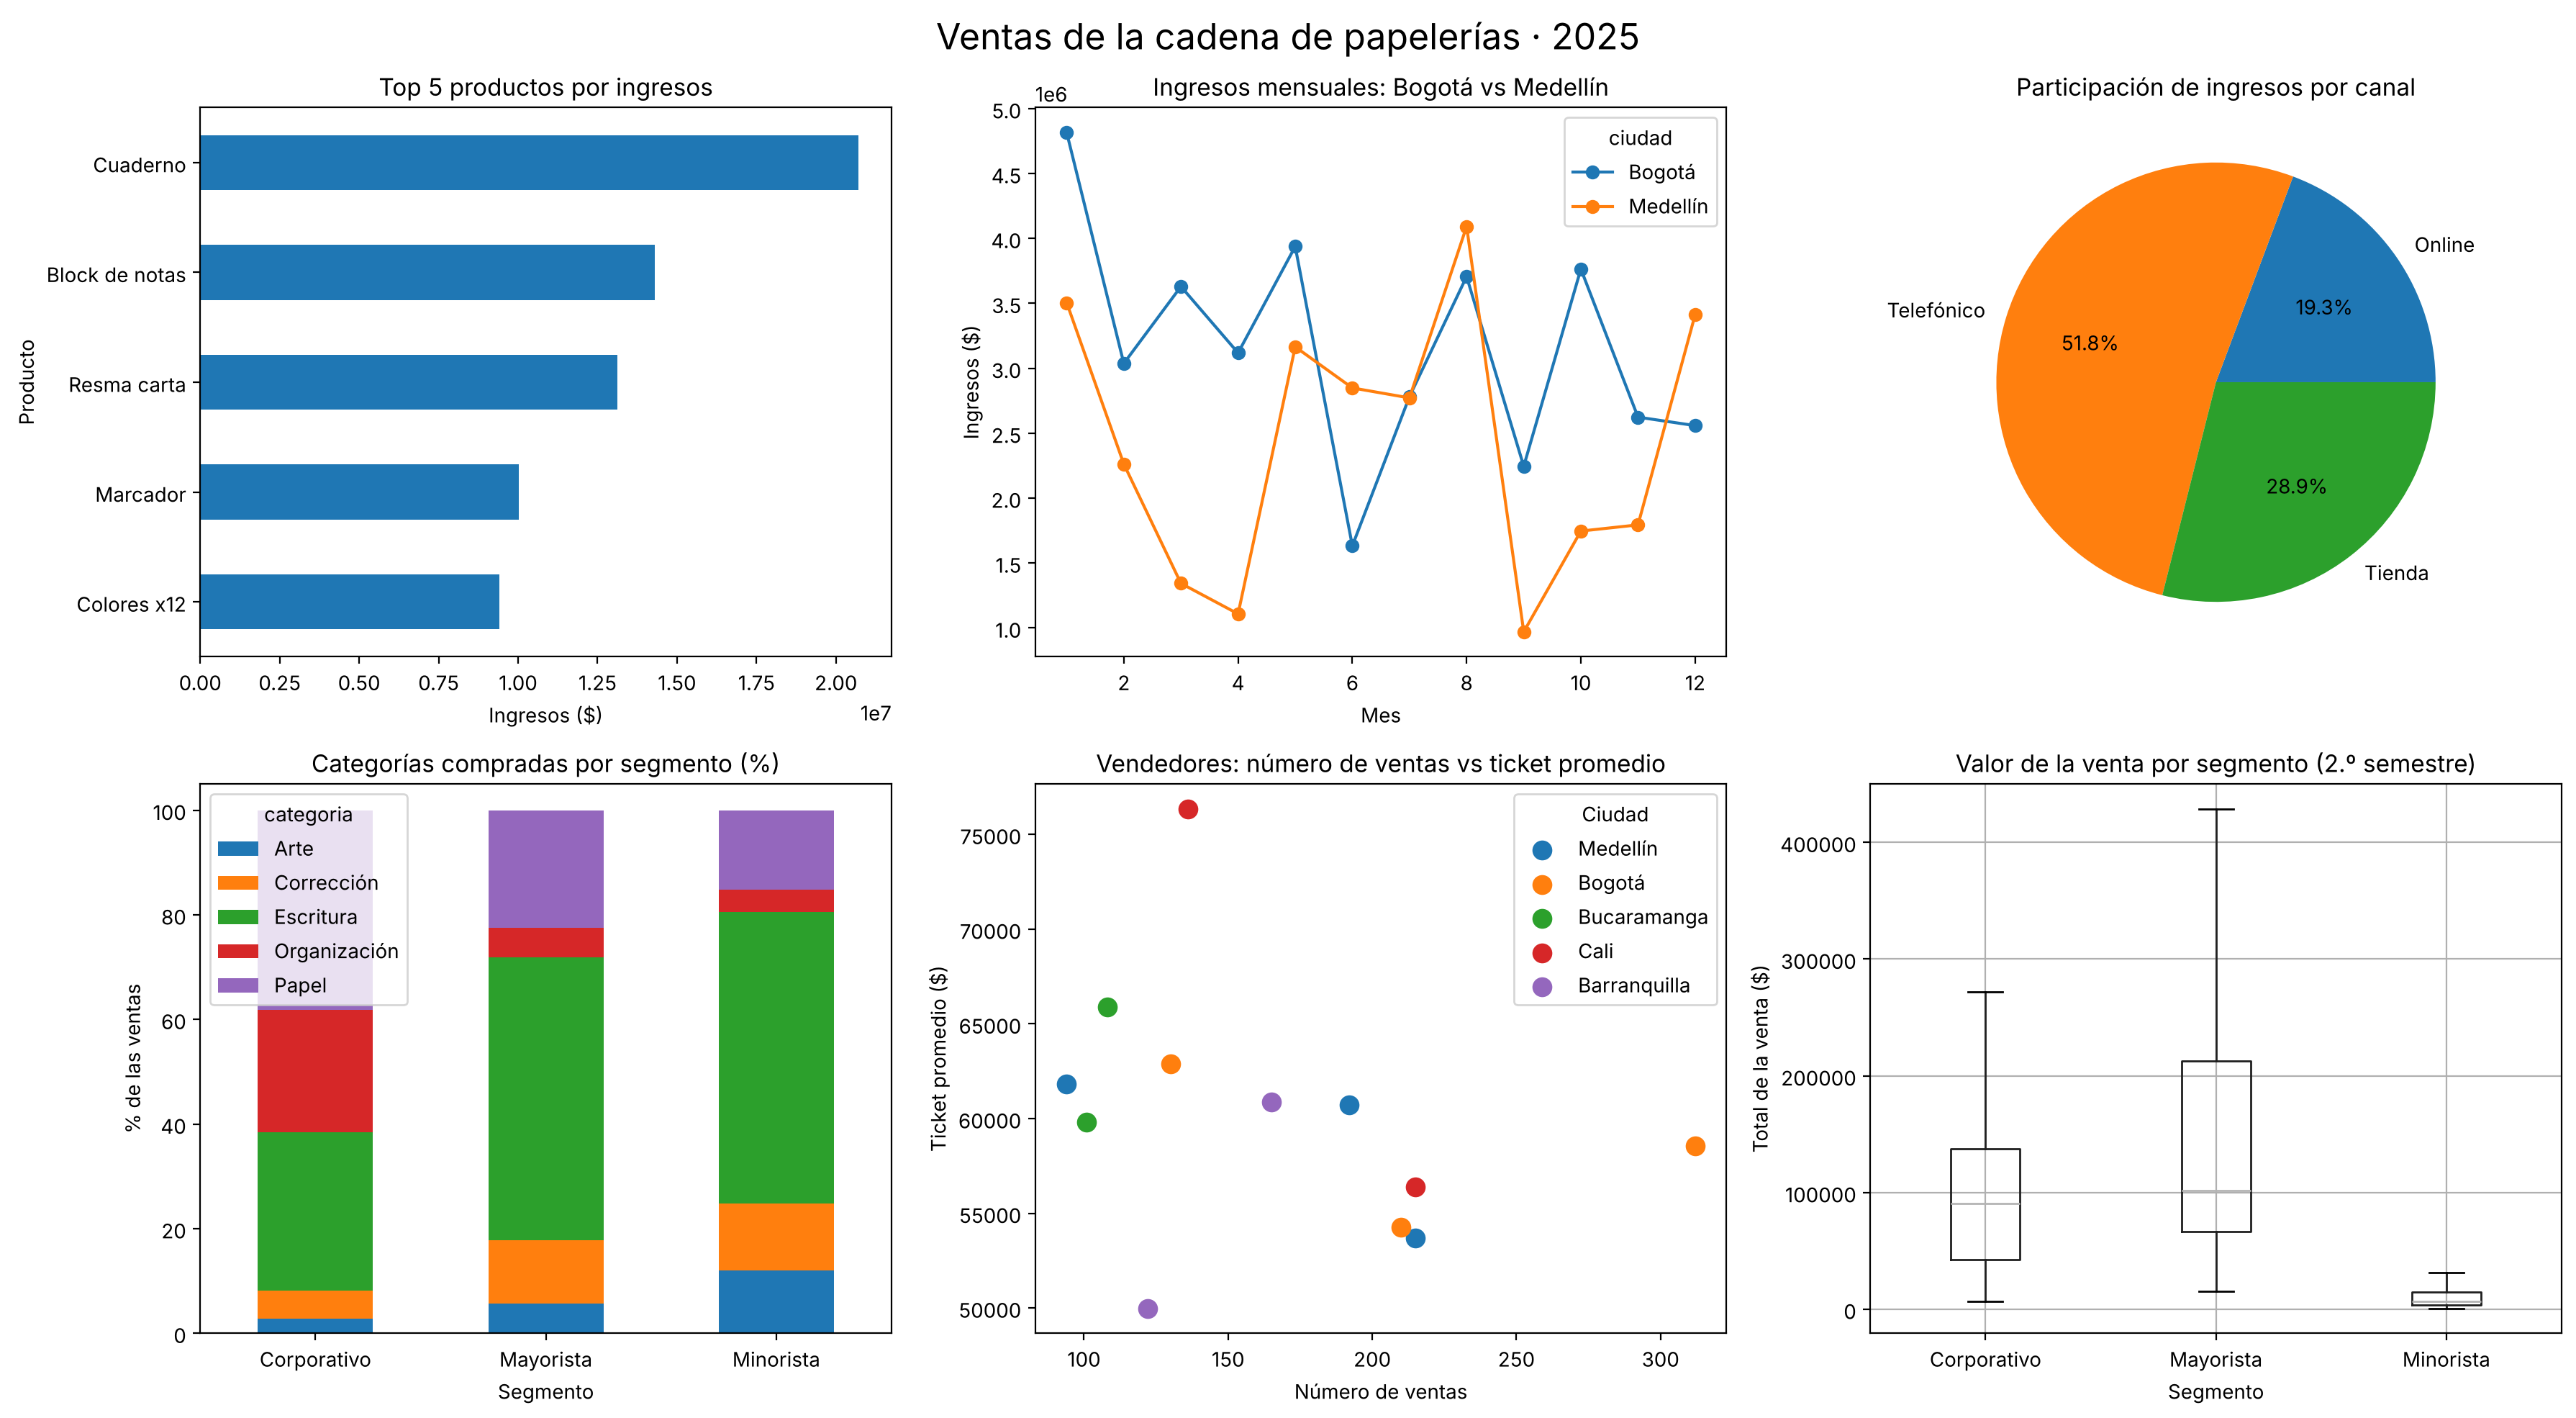

In [16]:
%run -i figura_base.py

In [17]:
# ✅ Verificación
assert len(fig.axes) >= 6, f"La figura debe tener 6 gráficos, tiene {len(fig.axes)}"
print("Ejercicio 7 correcto ✔")

Ejercicio 7 correcto ✔


---
# Parte C · Hazla ver bonita con prompts
Ahora **tú escribes el prompt** y se lo envías a Gemini (en [gemini.google.com](https://gemini.google.com) o la IA que prefieras). Gemini **reescribe el código** de tu figura para que se vea profesional, casi como un dashboard. Tú pegas ese código en el notebook y lo ejecutas.

**El ciclo, cada vez:**
1. Ejecuta la celda de herramientas: te muestra **tu código actual** y las **reglas técnicas**.
2. Escribe tu prompt (Ejercicios 8 y 9).
3. En el chat de la IA pega, en este orden: **tu prompt + tu código + las reglas**.
4. Copia **solo el código** de la respuesta (botón *copiar* del bloque) y pégalo en la celda `%%writefile figura_v1.py`. **No incluyas las líneas con \`\`\`** ni el texto que la IA escriba fuera del bloque.
5. Ejecuta la celda y luego `mostrar("v1")` para ver la figura.

### Herramientas *(ya están hechas)*
Ejecuta la celda: define la función `mostrar(nombre)` (dibuja la versión guardada en `figura_<nombre>.py`) e imprime lo que debes copiar a la IA.

In [18]:
REGLAS_FIGURA = """

Reglas técnicas obligatorias:
- Usa solo pandas y matplotlib (y numpy si lo necesitas). No instales otras librerías.
- Los datos ya están cargados en el DataFrame `df` (columnas: id_venta, fecha, ciudad, canal, segmento, vendedor,
  producto, categoria, metodo_pago, cantidad, precio_unitario, descuento, total, mes). No cargues archivos.
- Conserva los MISMOS 6 gráficos y los mismos datos del código actual; cambia solo la presentación.
- La figura debe quedar en una variable llamada `fig` (2 filas x 3 columnas).
- NO uses plt.show() ni guardes archivos.
- Entrega solo UN bloque de código Python completo.
"""


def mostrar(nombre):
    """Dibuja la versión guardada en figura_<nombre>.py."""
    plt.close("all")
    codigo = open(f"figura_{nombre}.py", encoding="utf-8").read().replace("plt.show()", "")
    exec(codigo, globals())
    display(fig)
    plt.close(fig)


print("=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===")
print(open("figura_base.py", encoding="utf-8").read())
print("\n=== 2) COPIA ESTAS REGLAS al final de tu prompt ===")
print(REGLAS_FIGURA)

=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===
# Ejercicio 7: figura 2x3 con los seis gráficos
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# 1) Top 5 productos (barras horizontales)
top_productos.sort_values().plot.barh(ax=axs[0, 0], title="Top 5 productos por ingresos")
axs[0, 0].set_xlabel("Ingresos ($)")
axs[0, 0].set_ylabel("Producto")

# 2) Ingresos mes a mes: Bogotá vs Medellín (líneas)
ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o", title="Ingresos mensuales: Bogotá vs Medellín")
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos ($)")

# 3) Participación por canal (pie)
ing_canal.plot.pie(ax=axs[0, 2], autopct="%.1f%%", title="Participación de ingresos por canal")
axs[0, 2].set_ylabel("")

# 4) Segmento vs categoría (barras apiladas)
tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True, title="Categorías compradas por segmento (%)")
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("% de las ventas")
axs[1, 0].tick_params(axis="x", rotation=0)

# 5) Productivi

### Ejercicio 8 · Tu primer prompt de estilo
Completa las secciones de `prompt_v1`. Sé **específico**: "usa una paleta de azules y naranja" funciona mejor que "hazlo bonito".

- **PÚBLICO Y OBJETIVO:** quién verá la figura y para qué.
- **PALETA Y TIPOGRAFÍA:** colores (por ciudad, por producto…), fondo, tamaños de letra.
- **TÍTULOS:** que cada gráfico tenga un título que diga la **conclusión** (por ejemplo, "Bogotá lidera las ventas"), no solo el nombre.
- **EJES Y NÚMEROS:** formatos con separador de miles o "$ 12 M", etiquetas de ejes claras.
- **LIMPIEZA VISUAL:** quitar bordes y marcos innecesarios, cuadrícula suave, valores sobre las barras.

Ejecuta la primera celda para imprimir tu prompt y cópialo a la IA (con tu código y las reglas). Luego pega el código que te devuelva en la segunda celda y muestra la figura con la tercera.

In [19]:
prompt_v1 = """
PÚBLICO Y OBJETIVO: La figura la verá la gerencia de la cadena de papelerías en una junta, proyectada en pantalla grande. Debe poder leerse en menos de un minuto y mostrar de un vistazo qué producto, ciudad, canal y segmento pesan más en las ventas de 2025. Hazla con aspecto de dashboard profesional, limpio y sobrio.

PALETA Y TIPOGRAFÍA: Fondo gris muy claro (#F3F4F6) y paneles blancos. Usa un color fijo por ciudad en todos los gráficos donde aparezcan: Bogotá azul oscuro (#1F3A5F), Medellín naranja (#F28E2B), Cali verde (#2E9E6B), Barranquilla amarillo (#E8C547), Bucaramanga violeta (#7B5EA7). Las barras con una sola serie en azul oscuro. Fuente sans-serif; títulos en negrita alineados a la izquierda (tamaño 12), texto gris oscuro, ejes en gris medio. Título general grande, en negrita y alineado a la izquierda.

TÍTULOS: Cada gráfico debe tener un título que diga la conclusión calculada a partir de los datos, no solo el nombre. Por ejemplo: "Cuaderno lidera con $ 20.7 M", "Bogotá supera a Medellín en 9 de 12 meses", "Canal Telefónico: 51.8 % de los ingresos", "Corporativo compra más Papel y Organización", "Laura Gómez lidera con 312 ventas". Calcula los números en el código para que no queden escritos a mano.

EJES Y NÚMEROS: Los pesos en millones con formato "$ 20 M" (barras y líneas) y en miles con formato "$ 60 mil" (dispersión y cajas), nunca en notación científica. Etiquetas de ejes claras y cortas. En el eje X de las líneas usa la inicial de cada mes (E, F, M, A...). Muestra el valor al final de cada barra y el porcentaje dentro de cada tramo de las barras apiladas (solo si es mayor o igual a 8 %).

LIMPIEZA VISUAL: Quita los bordes y marcos de los gráficos, deja solo una cuadrícula muy suave del color #E5E7EB detrás de los datos, sin marcas (ticks) en los ejes. Leyendas sin marco y fuera del área de datos cuando se pueda. Sin sombras ni adornos innecesarios.
"""

print(prompt_v1)    # cópialo en la IA, junto con tu código y las reglas


PÚBLICO Y OBJETIVO: La figura la verá la gerencia de la cadena de papelerías en una junta, proyectada en pantalla grande. Debe poder leerse en menos de un minuto y mostrar de un vistazo qué producto, ciudad, canal y segmento pesan más en las ventas de 2025. Hazla con aspecto de dashboard profesional, limpio y sobrio.

PALETA Y TIPOGRAFÍA: Fondo gris muy claro (#F3F4F6) y paneles blancos. Usa un color fijo por ciudad en todos los gráficos donde aparezcan: Bogotá azul oscuro (#1F3A5F), Medellín naranja (#F28E2B), Cali verde (#2E9E6B), Barranquilla amarillo (#E8C547), Bucaramanga violeta (#7B5EA7). Las barras con una sola serie en azul oscuro. Fuente sans-serif; títulos en negrita alineados a la izquierda (tamaño 12), texto gris oscuro, ejes en gris medio. Título general grande, en negrita y alineado a la izquierda.

TÍTULOS: Cada gráfico debe tener un título que diga la conclusión calculada a partir de los datos, no solo el nombre. Por ejemplo: "Cuaderno lidera con $ 20.7 M", "Bogotá su

In [20]:
%%writefile figura_v1.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ---------- Estilo ----------
FONDO, PANEL, TEXTO, GRIS, REJILLA = "#F3F4F6", "#FFFFFF", "#1F2937", "#6B7280", "#E5E7EB"
CIUDAD = {"Bogotá": "#1F3A5F", "Medellín": "#F28E2B", "Cali": "#2E9E6B",
          "Barranquilla": "#E8C547", "Bucaramanga": "#7B5EA7"}
CATEG = {"Arte": "#F28E2B", "Corrección": "#E8C547", "Escritura": "#1F3A5F",
         "Organización": "#2E9E6B", "Papel": "#9CA3AF"}
CANAL = {"Telefónico": "#1F3A5F", "Tienda": "#F28E2B", "Online": "#2E9E6B"}
plt.rcParams.update({"font.family": "sans-serif", "text.color": TEXTO,
                     "axes.labelcolor": GRIS, "xtick.color": GRIS, "ytick.color": GRIS})
millones = FuncFormatter(lambda x, _: f"$ {x/1e6:,.0f} M")
miles = FuncFormatter(lambda x, _: f"$ {x/1e3:,.0f} mil")

def limpiar(ax, rejilla="y"):
    ax.set_facecolor(PANEL)
    for lado in ("top", "right", "left", "bottom"):
        ax.spines[lado].set_visible(False)
    ax.grid(axis=rejilla, color=REJILLA, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, labelsize=10)

def titulo(ax, texto):
    ax.set_title(texto, loc="left", fontsize=12, fontweight="bold", color=TEXTO, pad=12)

# ---------- Datos (mismos del taller) ----------
top = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
mes = (df[df["ciudad"].isin(["Bogotá", "Medellín"])]
       .pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum"))
canal = df.groupby("canal")["total"].sum().sort_values(ascending=False)
seg = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
v = (df.groupby(["vendedor", "ciudad"])
       .agg(n_ventas=("total", "size"), ticket_prom=("total", "mean")).reset_index())
s2 = df[df["mes"] >= 7]

fig, axs = plt.subplots(2, 3, figsize=(18, 10))
fig.patch.set_facecolor(FONDO)

# 1) Top 5 productos
ax = axs[0, 0]; limpiar(ax, "x")
t = top.sort_values()
barras = ax.barh(t.index, t.values, color="#1F3A5F", height=0.6)
for b, val in zip(barras, t.values):
    ax.text(val, b.get_y() + b.get_height()/2, f"  $ {val/1e6:.1f} M", va="center", fontsize=10, color=TEXTO)
ax.xaxis.set_major_formatter(millones); ax.set_xlim(0, t.max()*1.2)
ax.set_xlabel("Ingresos 2025"); titulo(ax, f"{top.index[0]} lidera con $ {top.iloc[0]/1e6:.1f} M")

# 2) Líneas mensuales
ax = axs[0, 1]; limpiar(ax, "y")
for c in mes.columns:
    ax.plot(mes.index, mes[c], marker="o", color=CIUDAD[c], linewidth=2.2, label=c)
ax.yaxis.set_major_formatter(millones)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("EFMAMJJASOND"))
ax.set_xlabel("Mes de 2025"); ax.legend(frameon=False, fontsize=10)
n = int((mes["Bogotá"] > mes["Medellín"]).sum())
titulo(ax, f"Bogotá supera a Medellín en {n} de 12 meses")

# 3) Pie por canal
ax = axs[0, 2]; ax.set_facecolor(PANEL)
ax.pie(canal.values, labels=canal.index, colors=[CANAL[c] for c in canal.index],
       autopct="%.1f%%", startangle=90, counterclock=False,
       wedgeprops={"edgecolor": "white", "linewidth": 2},
       textprops={"fontsize": 11, "color": TEXTO})
ax.set_ylabel("")
titulo(ax, f"Canal {canal.index[0]}: {canal.iloc[0]/canal.sum()*100:.1f} % de los ingresos")

# 4) Barras apiladas
ax = axs[1, 0]; limpiar(ax, "y")
base = np.zeros(len(seg))
for c in seg.columns:
    ax.bar(seg.index, seg[c], bottom=base, color=CATEG[c], label=c, width=0.6)
    for i, val in enumerate(seg[c]):
        if val >= 8:
            ax.text(i, base[i] + val/2, f"{val:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if c in ("Escritura", "Organización") else TEXTO)
    base += seg[c].values
ax.set_ylim(0, 100); ax.set_ylabel("% de las ventas")
ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
titulo(ax, "Corporativo compra más Papel y Organización")

# 5) Dispersión
ax = axs[1, 1]; limpiar(ax, "both")
for c, sub in v.groupby("ciudad"):
    ax.scatter(sub["n_ventas"], sub["ticket_prom"], s=110, color=CIUDAD[c], label=c, edgecolor="white")
ax.yaxis.set_major_formatter(miles)
ax.set_xlabel("Número de ventas"); ax.set_ylabel("Ticket promedio")
ax.legend(frameon=False, fontsize=9, title="Ciudad", title_fontsize=9)
mx = v.loc[v["n_ventas"].idxmax()]
titulo(ax, f"{mx['vendedor']} lidera con {int(mx['n_ventas'])} ventas")

# 6) Cajas
ax = axs[1, 2]; limpiar(ax, "y")
orden = ["Minorista", "Mayorista", "Corporativo"]
bp = ax.boxplot([s2[s2["segmento"] == s]["total"] for s in orden], showfliers=False,
                patch_artist=True, medianprops={"color": TEXTO, "linewidth": 2})
ax.set_xticklabels(orden)
for caja in bp["boxes"]:
    caja.set(facecolor="#9DB4D3", edgecolor="#1F3A5F")
ax.yaxis.set_major_formatter(miles); ax.set_ylabel("Valor de la venta (2.º semestre)")
titulo(ax, "Mayorista y Corporativo venden tickets más grandes")

fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=20, fontweight="bold",
             x=0.02, ha="left", color=TEXTO)
plt.tight_layout(rect=[0, 0, 1, 0.95])


Writing figura_v1.py


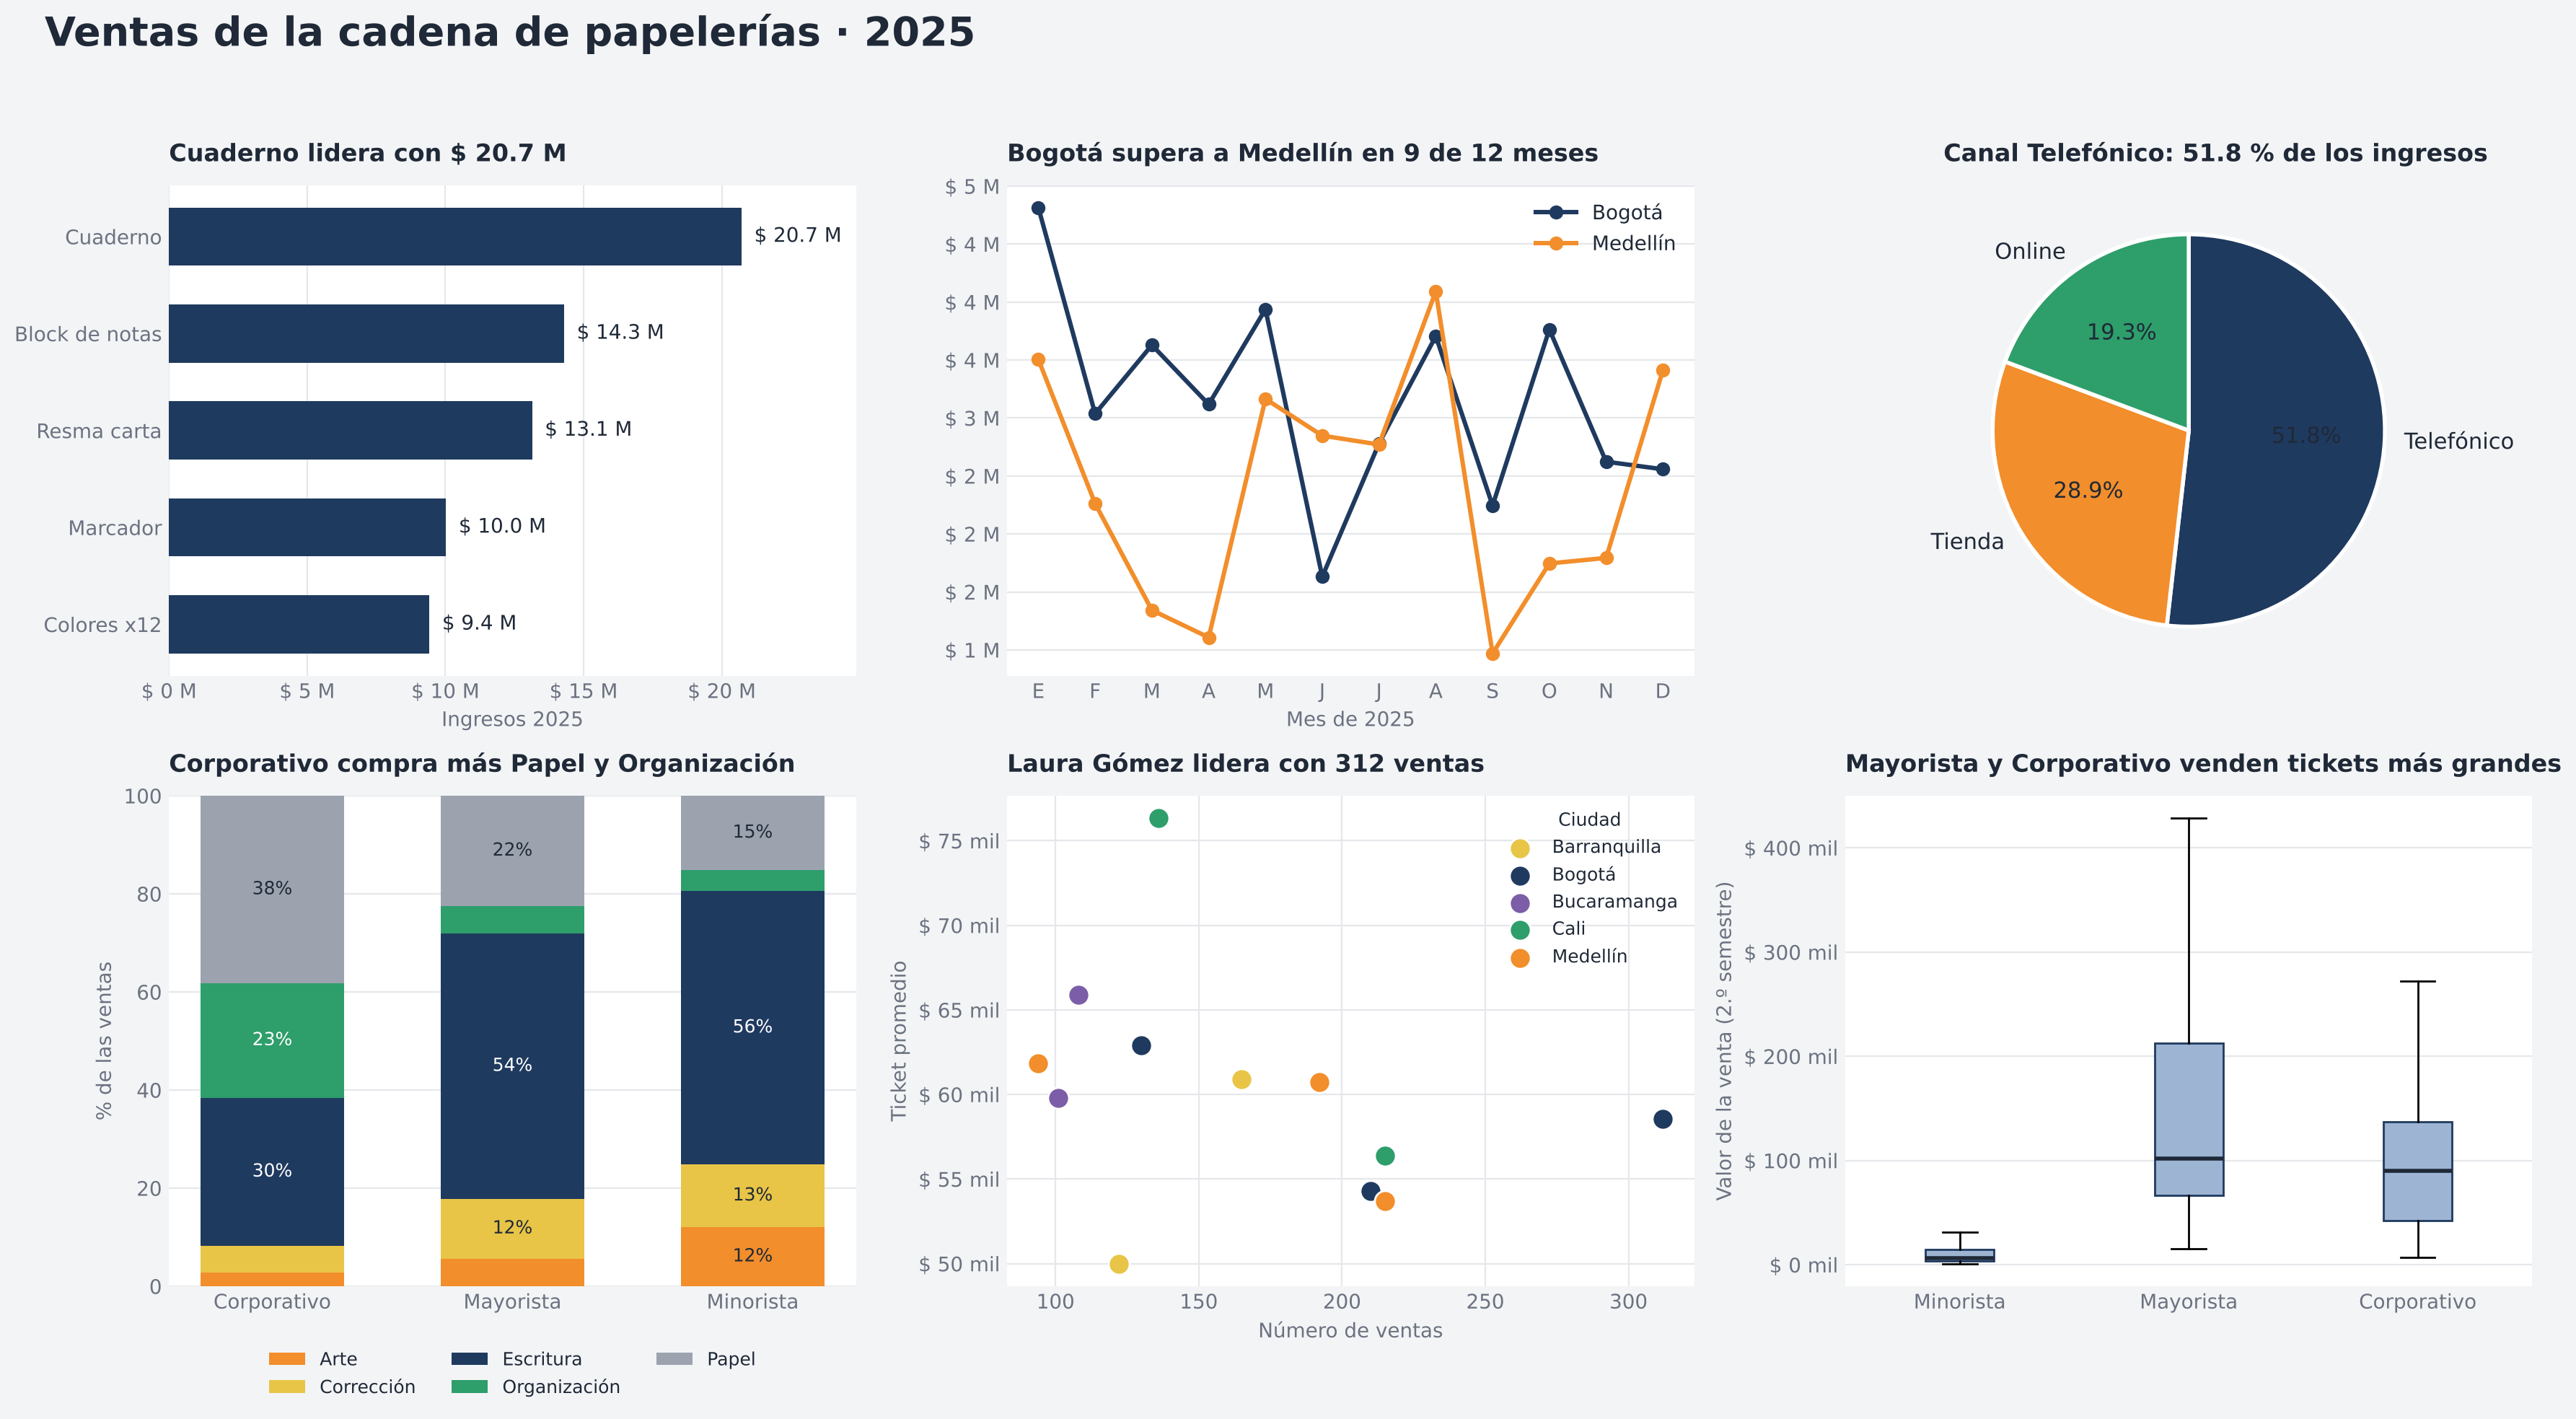

In [21]:
mostrar("v1")

### Ejercicio 9 · Itera: mejora tu prompt
Mira la figura que obtuviste: ¿qué no te gusta? Agrega una sección **AJUSTES** con **al menos dos cambios concretos** (otra paleta, letras más grandes, una dona en lugar del pie, anotar el valor máximo del gráfico de líneas…). Es la **iteración de prompts** que vimos en clase. Repite el ciclo: copia `prompt_v2` a la IA (con tu código base y las reglas), pega el código en `figura_v2.py` y muestra la figura.

In [22]:
prompt_v2 = prompt_v1 + """

AJUSTES (sobre la versión anterior, mantén todo lo demás igual):
1. El gráfico de líneas repetía "$ 4 M" en varias marcas del eje Y porque redondeaba sin decimales: usa un decimal ("$ 4.5 M") y anota con una flecha corta el valor máximo mensual (valor, ciudad y mes).
2. En el gráfico de pie el porcentaje del canal Telefónico (51.8 %) quedaba oscuro sobre el azul oscuro y no se leía: cámbialo por una dona (anillo delgado), porcentajes en blanco y negrita, y escribe el ingreso total de la cadena en el centro ("$ 119 M").
3. Las letras se ven pequeñas para una junta: sube los títulos a 14, las marcas de los ejes a 12, las leyendas a 11 y el título general a 22. Si un título queda cortado, pártelo en dos líneas.
4. En la dispersión escribe el nombre del vendedor con más ventas y el del ticket promedio más alto, para saber quién es cada punto.
"""

print(prompt_v2)


PÚBLICO Y OBJETIVO: La figura la verá la gerencia de la cadena de papelerías en una junta, proyectada en pantalla grande. Debe poder leerse en menos de un minuto y mostrar de un vistazo qué producto, ciudad, canal y segmento pesan más en las ventas de 2025. Hazla con aspecto de dashboard profesional, limpio y sobrio.

PALETA Y TIPOGRAFÍA: Fondo gris muy claro (#F3F4F6) y paneles blancos. Usa un color fijo por ciudad en todos los gráficos donde aparezcan: Bogotá azul oscuro (#1F3A5F), Medellín naranja (#F28E2B), Cali verde (#2E9E6B), Barranquilla amarillo (#E8C547), Bucaramanga violeta (#7B5EA7). Las barras con una sola serie en azul oscuro. Fuente sans-serif; títulos en negrita alineados a la izquierda (tamaño 12), texto gris oscuro, ejes en gris medio. Título general grande, en negrita y alineado a la izquierda.

TÍTULOS: Cada gráfico debe tener un título que diga la conclusión calculada a partir de los datos, no solo el nombre. Por ejemplo: "Cuaderno lidera con $ 20.7 M", "Bogotá su

In [23]:
%%writefile figura_v2.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ---------- Estilo ----------
FONDO, PANEL, TEXTO, GRIS, REJILLA = "#F3F4F6", "#FFFFFF", "#1F2937", "#6B7280", "#E5E7EB"
CIUDAD = {"Bogotá": "#1F3A5F", "Medellín": "#F28E2B", "Cali": "#2E9E6B",
          "Barranquilla": "#E8C547", "Bucaramanga": "#7B5EA7"}
CATEG = {"Arte": "#F28E2B", "Corrección": "#E8C547", "Escritura": "#1F3A5F",
         "Organización": "#2E9E6B", "Papel": "#9CA3AF"}
CANAL = {"Telefónico": "#1F3A5F", "Tienda": "#F28E2B", "Online": "#2E9E6B"}
plt.rcParams.update({"font.family": "sans-serif", "text.color": TEXTO,
                     "axes.labelcolor": GRIS, "axes.labelsize": 12, "xtick.color": GRIS, "ytick.color": GRIS})
millones = FuncFormatter(lambda x, _: f"$ {x/1e6:,.0f} M")
millones1 = FuncFormatter(lambda x, _: f"$ {x/1e6:,.1f} M")
miles = FuncFormatter(lambda x, _: f"$ {x/1e3:,.0f} mil")

def limpiar(ax, rejilla="y"):
    ax.set_facecolor(PANEL)
    for lado in ("top", "right", "left", "bottom"):
        ax.spines[lado].set_visible(False)
    ax.grid(axis=rejilla, color=REJILLA, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, labelsize=12)

def titulo(ax, texto):
    ax.set_title(texto, loc="left", fontsize=14, fontweight="bold", color=TEXTO, pad=14)

# ---------- Datos (mismos del taller) ----------
top = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
mes = (df[df["ciudad"].isin(["Bogotá", "Medellín"])]
       .pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum"))
canal = df.groupby("canal")["total"].sum().sort_values(ascending=False)
seg = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
v = (df.groupby(["vendedor", "ciudad"])
       .agg(n_ventas=("total", "size"), ticket_prom=("total", "mean")).reset_index())
s2 = df[df["mes"] >= 7]

fig, axs = plt.subplots(2, 3, figsize=(18, 10))
fig.patch.set_facecolor(FONDO)

# 1) Top 5 productos
ax = axs[0, 0]; limpiar(ax, "x")
t = top.sort_values()
barras = ax.barh(t.index, t.values, color="#1F3A5F", height=0.6)
for b, val in zip(barras, t.values):
    ax.text(val, b.get_y() + b.get_height()/2, f"  $ {val/1e6:.1f} M", va="center", fontsize=12, color=TEXTO)
ax.xaxis.set_major_formatter(millones); ax.set_xlim(0, t.max()*1.2)
ax.set_xlabel("Ingresos 2025"); titulo(ax, f"{top.index[0]} lidera\ncon $ {top.iloc[0]/1e6:.1f} M")

# 2) Líneas mensuales
ax = axs[0, 1]; limpiar(ax, "y")
for c in mes.columns:
    ax.plot(mes.index, mes[c], marker="o", color=CIUDAD[c], linewidth=2.2, label=c)
ax.yaxis.set_major_formatter(millones1)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("EFMAMJJASOND"))
ax.set_xlabel("Mes de 2025"); ax.legend(frameon=False, fontsize=12)
mm = mes.stack().idxmax(); vmax = mes.stack().max()
ax.annotate(f"Máx.: $ {vmax/1e6:.1f} M\n({mm[1]}, mes {mm[0]})", xy=(mm[0], vmax), xytext=(mm[0]+1.2, vmax),
            fontsize=11, fontweight="bold", va="center", arrowprops={"arrowstyle": "-", "color": GRIS})
ax.set_ylim(top=vmax*1.08)
n = int((mes["Bogotá"] > mes["Medellín"]).sum())
titulo(ax, f"Bogotá supera a Medellín\nen {n} de 12 meses")

# 3) Dona por canal
ax = axs[0, 2]; ax.set_facecolor(PANEL)
ax.pie(canal.values, labels=canal.index, colors=[CANAL[c] for c in canal.index],
       autopct="%.1f%%", pctdistance=0.76, startangle=90, counterclock=False,
       wedgeprops={"edgecolor": "white", "linewidth": 2, "width": 0.45},
       textprops={"fontsize": 12, "color": TEXTO})
for t in ax.texts:
    if t.get_text().endswith("%"):
        t.set_color("white"); t.set_fontweight("bold")
ax.text(0, 0, f"$ {canal.sum()/1e6:.0f} M\ningresos", ha="center", va="center", fontsize=14, fontweight="bold")
titulo(ax, f"Canal {canal.index[0]}:\n{canal.iloc[0]/canal.sum()*100:.1f} % de los ingresos")

# 4) Barras apiladas
ax = axs[1, 0]; limpiar(ax, "y")
base = np.zeros(len(seg))
for c in seg.columns:
    ax.bar(seg.index, seg[c], bottom=base, color=CATEG[c], label=c, width=0.6)
    for i, val in enumerate(seg[c]):
        if val >= 8:
            ax.text(i, base[i] + val/2, f"{val:.0f}%", ha="center", va="center", fontsize=11,
                    color="white" if c in ("Escritura", "Organización") else TEXTO)
    base += seg[c].values
ax.set_ylim(0, 100); ax.set_ylabel("% de las ventas")
ax.legend(frameon=False, fontsize=11, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
titulo(ax, "Corporativo compra más Papel\ny Organización")

# 5) Dispersión
ax = axs[1, 1]; limpiar(ax, "both")
for c, sub in v.groupby("ciudad"):
    ax.scatter(sub["n_ventas"], sub["ticket_prom"], s=110, color=CIUDAD[c], label=c, edgecolor="white")
ax.yaxis.set_major_formatter(miles)
ax.set_xlabel("Número de ventas"); ax.set_ylabel("Ticket promedio")
ax.legend(frameon=False, fontsize=11, title="Ciudad", title_fontsize=11)
for _, r in v.nlargest(1, "n_ventas").iterrows():
    ax.annotate(r["vendedor"], (r["n_ventas"], r["ticket_prom"]), xytext=(-8, 12), textcoords="offset points",
                ha="right", fontsize=11)
r = v.loc[v["ticket_prom"].idxmax()]
ax.annotate(f"{r['vendedor']}\n(ticket más alto)", (r["n_ventas"], r["ticket_prom"]), xytext=(10, 0),
            textcoords="offset points", fontsize=11, va="center")
mx = v.loc[v["n_ventas"].idxmax()]
titulo(ax, f"{mx['vendedor']} lidera\ncon {int(mx['n_ventas'])} ventas")

# 6) Cajas
ax = axs[1, 2]; limpiar(ax, "y")
orden = ["Minorista", "Mayorista", "Corporativo"]
bp = ax.boxplot([s2[s2["segmento"] == s]["total"] for s in orden], showfliers=False,
                patch_artist=True, medianprops={"color": TEXTO, "linewidth": 2})
ax.set_xticklabels(orden)
for caja in bp["boxes"]:
    caja.set(facecolor="#9DB4D3", edgecolor="#1F3A5F")
ax.yaxis.set_major_formatter(miles); ax.set_ylabel("Valor de la venta (2.º semestre)")
titulo(ax, "Mayorista y Corporativo:\nventas de mayor valor")

fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=22, fontweight="bold",
             x=0.02, ha="left", color=TEXTO)
plt.tight_layout(rect=[0, 0, 1, 0.94])


Writing figura_v2.py


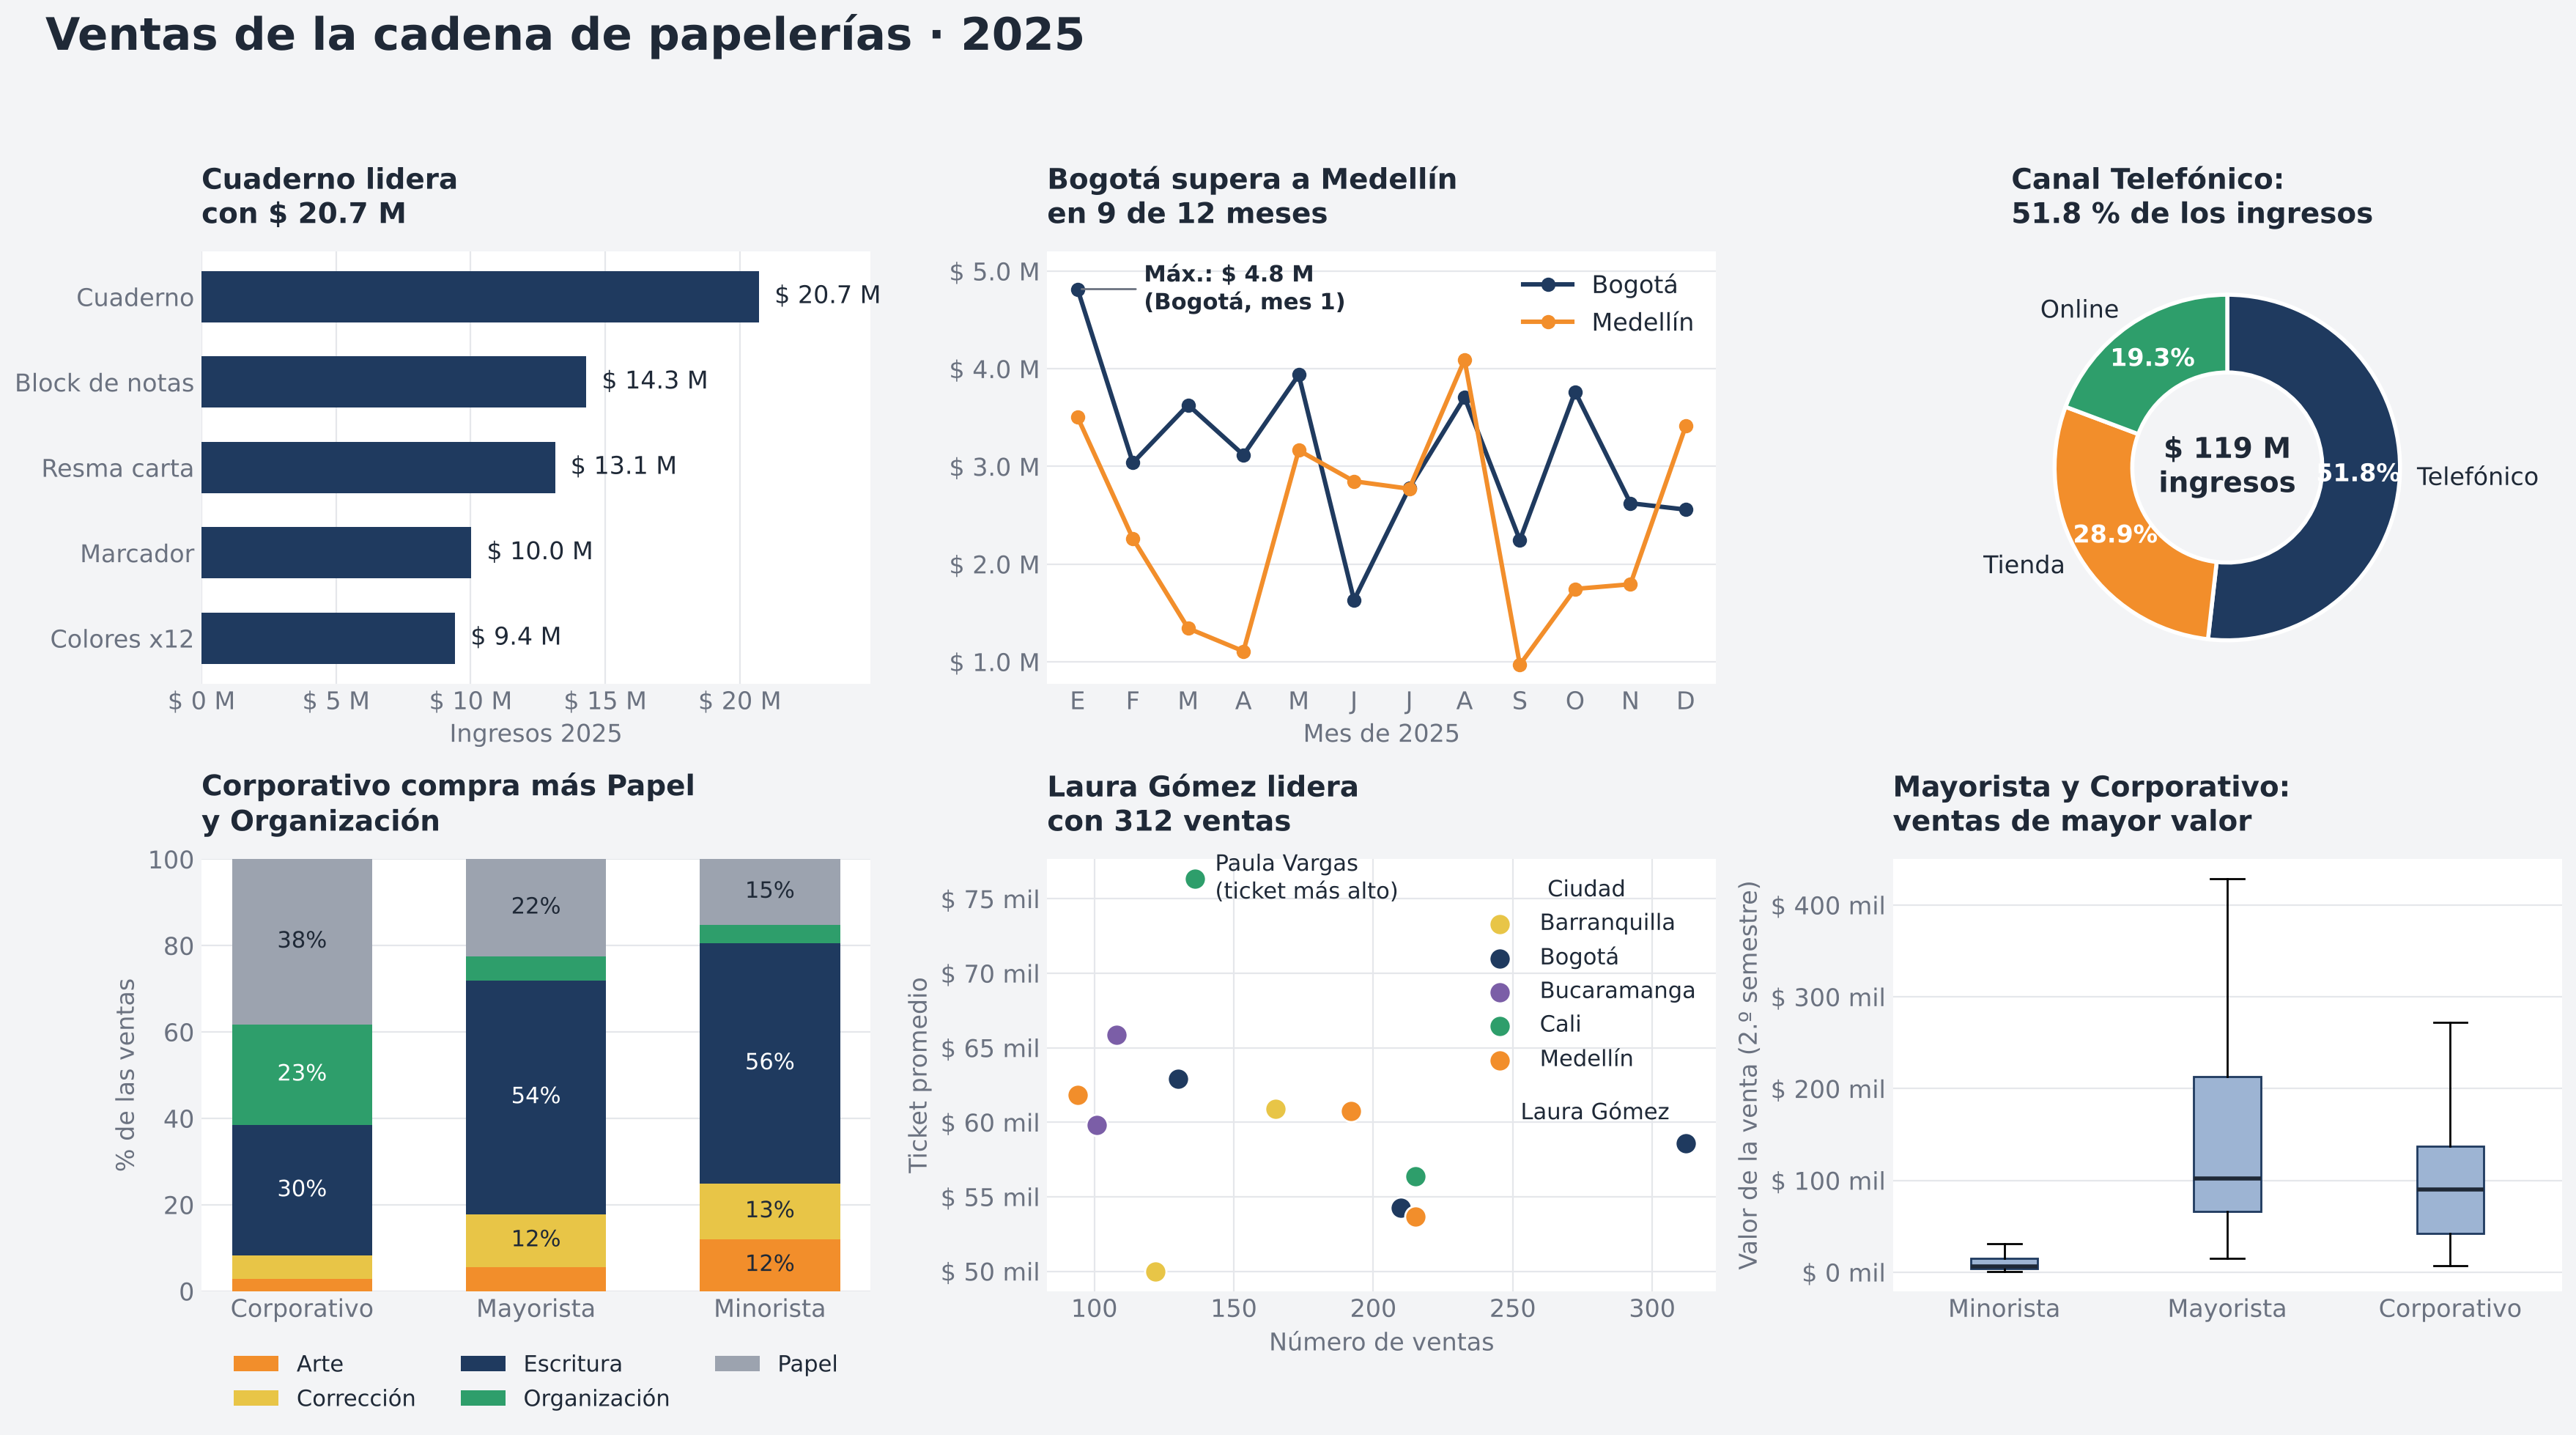

In [24]:
mostrar("v2")

### Ejercicio 10 *(opcional)* · Una tercera versión
Si quieres seguir mejorando, crea `prompt_v3` (parte de `prompt_v2`), repite el ciclo con `figura_v3.py` y muestra `mostrar("v3")`.

In [25]:
# prompt_v3 = prompt_v2 + """
#
# AJUSTES FINALES: ...
# """
# print(prompt_v3)

In [26]:
# ✅ Verificación
import os
assert os.path.exists("figura_v1.py") and os.path.exists("figura_v2.py"), "Faltan figura_v1.py y figura_v2.py: pega el código de cada versión"
assert "ESCRIBE AQUÍ" not in prompt_v1 and prompt_v2 != prompt_v1 and "ESCRIBE AQUÍ" not in prompt_v2, "Completa tus prompts v1 y v2"
print("Parte C correcta ✔")

Parte C correcta ✔


---
# Parte D · Elige tu favorita y publícala
### Ejercicio 11 · Tu dashboard final y tus conclusiones
Mira tus versiones y **elige la que más te guste**. Luego escribe **3 hallazgos**: frases cortas con **cifras reales** sacadas de tus tablas. Se mostrarán debajo de tu dashboard.

*Ejemplo de hallazgo:* "Bogotá genera el 32 % de los ingresos de la cadena."

In [27]:
figura_elegida = "v2"      # cambia por "v1", "v2" o "v3"

hallazgos = [
    "Bogotá genera el 31.9 % de los ingresos de la cadena ($ 37.8 M de $ 118.7 M) y es la ciudad que más vende, seguida de Medellín con $ 29.0 M.",
    "El canal Telefónico concentra el 51.8 % de los ingresos, casi el doble que la Tienda (28.9 %) y más de 2.5 veces el canal Online (19.3 %).",
    "Los clientes Corporativos compran Papel (38.2 %) y Organización (23.3 %), mientras que los Minoristas casi no compran Organización (4.3 %).",
]

In [28]:
# ✅ Verificación
import os
assert os.path.exists(f"figura_{figura_elegida}.py"), f"No existe figura_{figura_elegida}.py: revisa figura_elegida"
assert len(hallazgos) == 3 and all(len(h) > 25 and "ESCRIBE AQUÍ" not in h for h in hallazgos), "Escribe tus 3 hallazgos con cifras"
print("Ejercicio 11 correcto ✔")

Ejercicio 11 correcto ✔


### Tu dashboard final
Ejecuta la celda: muestra la versión que elegiste y tus tres hallazgos. **Esta es la salida que se verá en GitHub.**

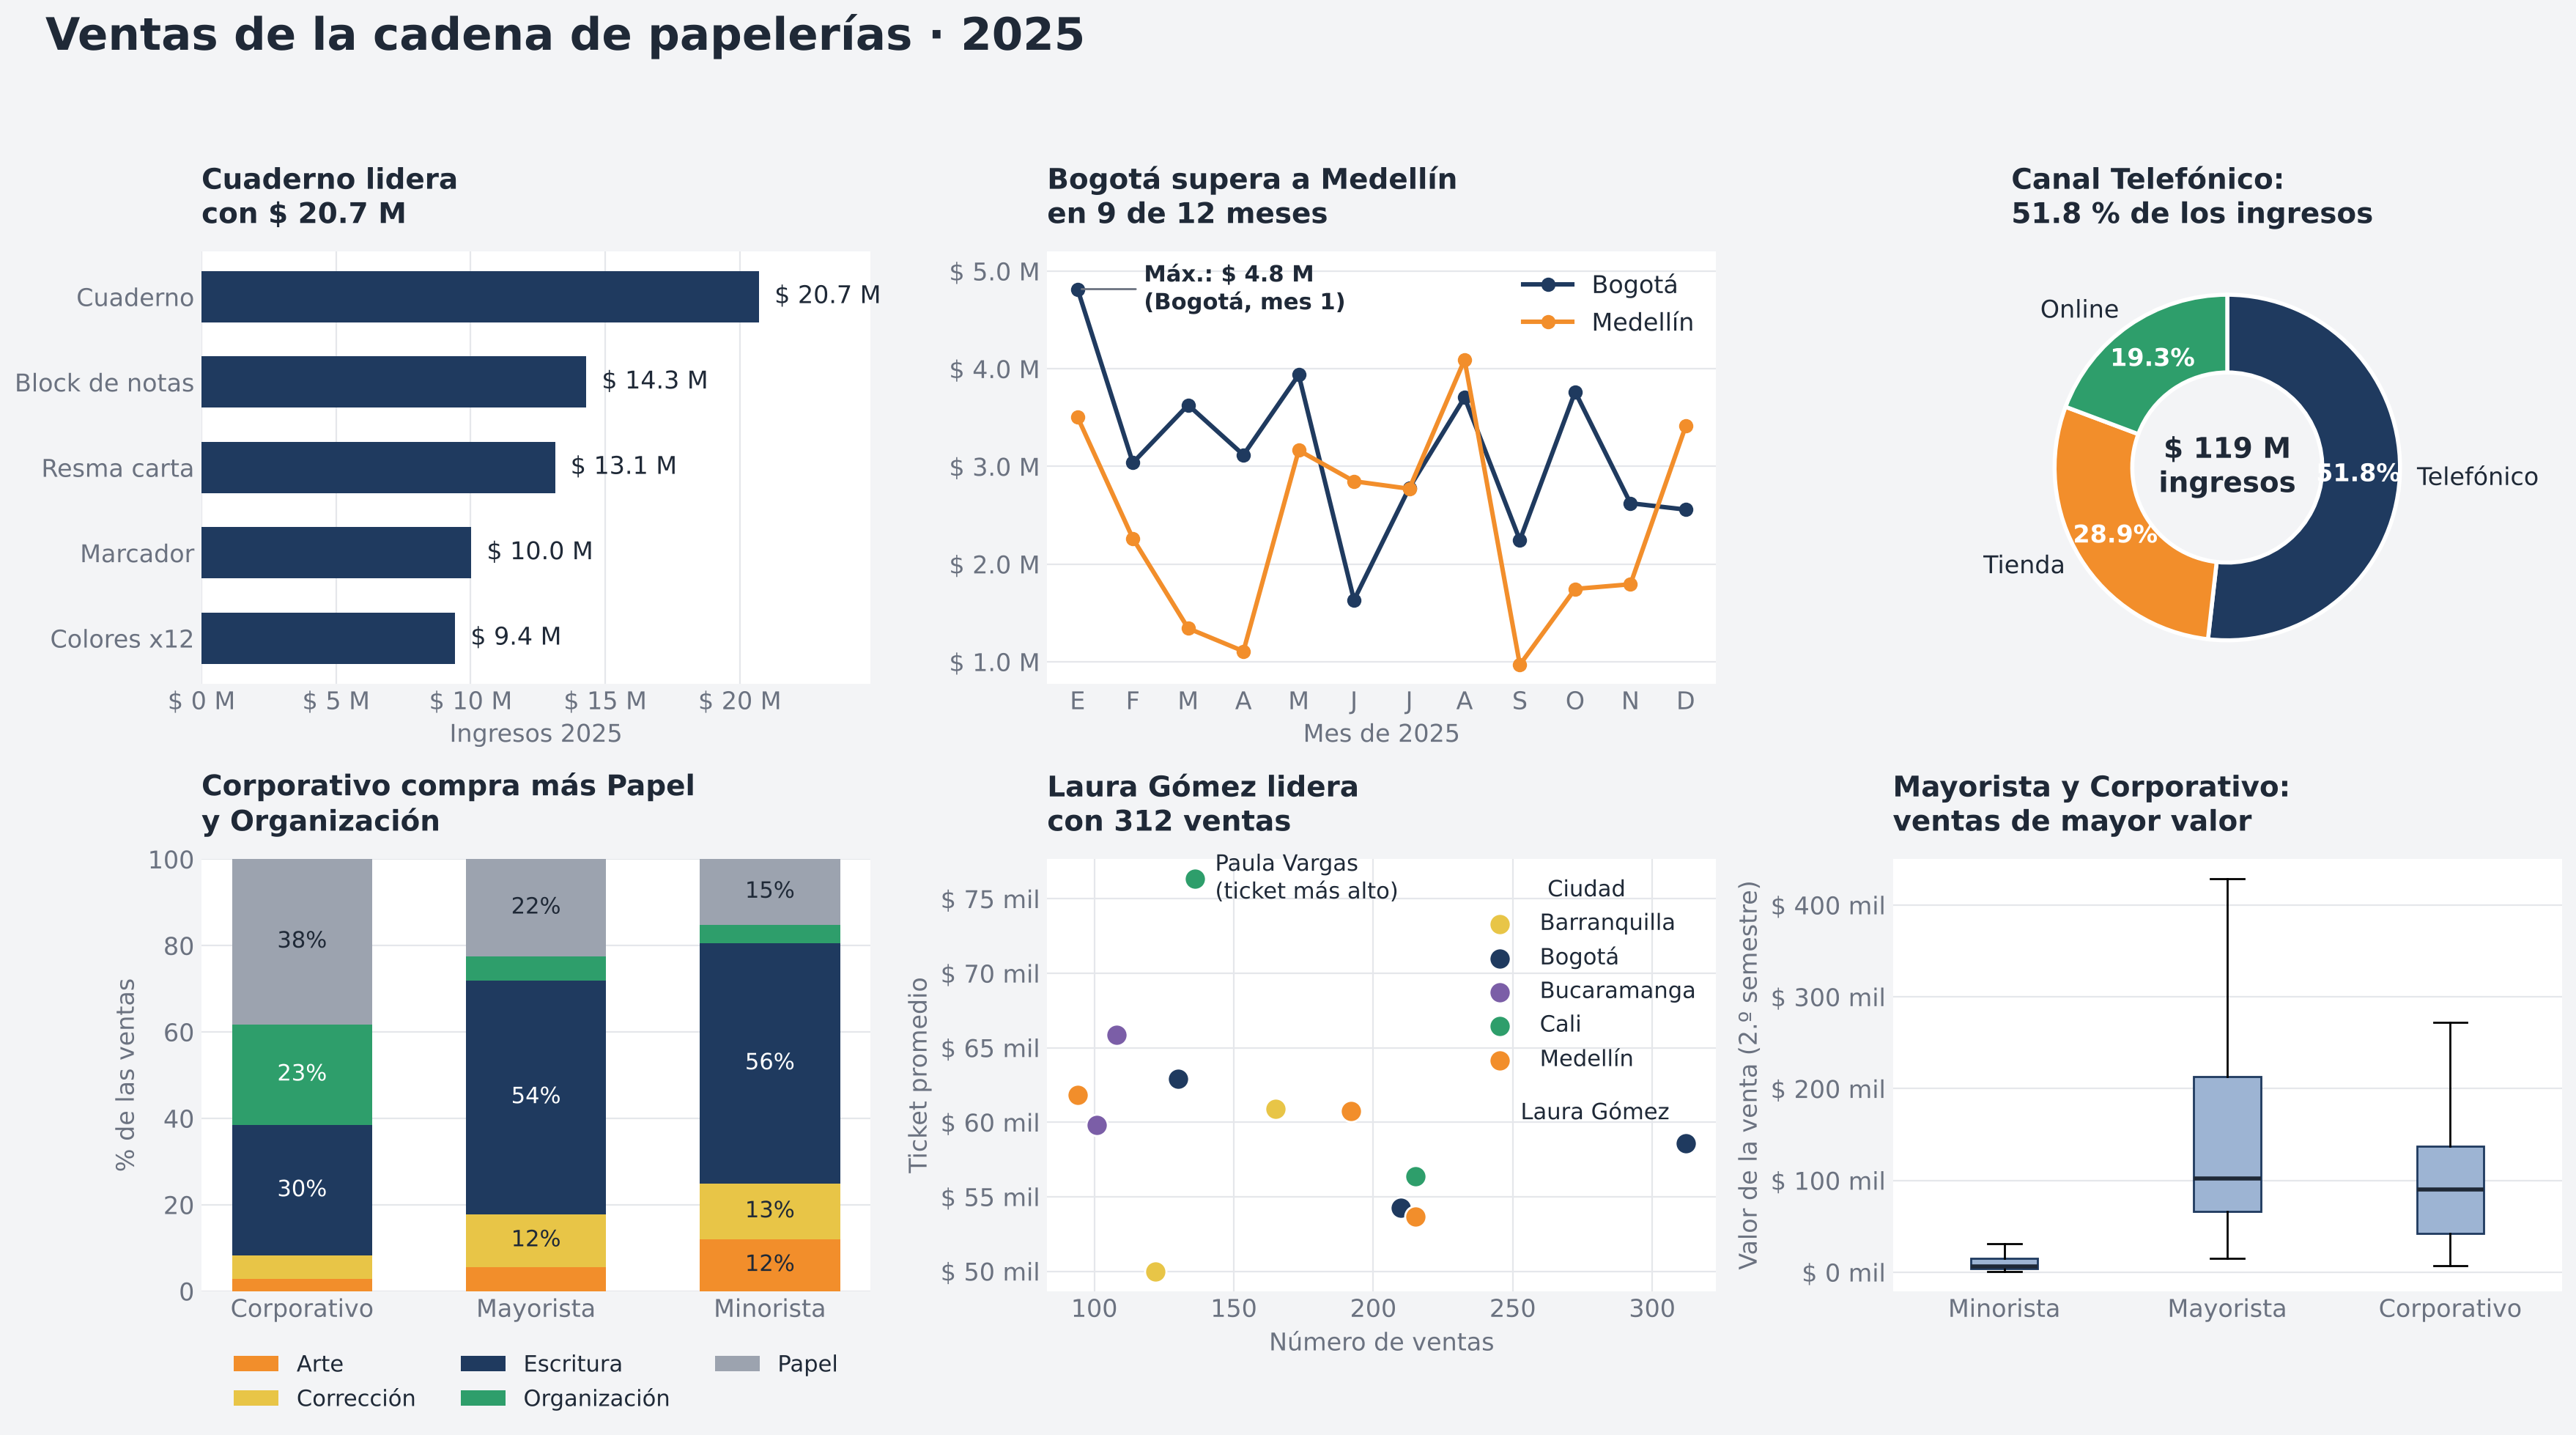

Hallazgos:
• Bogotá genera el 31.9 % de los ingresos de la cadena ($ 37.8 M de $ 118.7 M) y es la ciudad que más vende, seguida de Medellín con $ 29.0 M.
• El canal Telefónico concentra el 51.8 % de los ingresos, casi el doble que la Tienda (28.9 %) y más de 2.5 veces el canal Online (19.3 %).
• Los clientes Corporativos compran Papel (38.2 %) y Organización (23.3 %), mientras que los Minoristas casi no compran Organización (4.3 %).


In [29]:
mostrar(figura_elegida)

print("Hallazgos:")
for h in hallazgos:
    print("•", h)

### Ejercicio 12 · Publica tu notebook en GitHub
GitHub muestra los notebooks **con sus figuras**, así que tu notebook publicado es tu dashboard. Solo necesitas una cuenta gratuita en [github.com](https://github.com).

**Antes de publicar:**
- Ejecuta todo el notebook de arriba abajo (*Entorno de ejecución → Ejecutar todo*) para que las figuras queden guardadas en las salidas.
- **Nunca escribas tu API key dentro de una celda.** Los *Secrets* de Colab no se guardan en el notebook y por eso son seguros; el repositorio será público.

**Pasos:**
1. **Crea el repositorio:** botón **New** → nombre `mi-dashboard-ventas` → **Public** → *Create repository*.
2. **Guarda el notebook en GitHub.** Opción A: en Colab, *Archivo → Guardar una copia en GitHub*, autoriza, elige tu repositorio y acepta. Opción B: *Archivo → Descargar → .ipynb* y, en el repositorio, **Add file → Upload files** y arrastra el archivo.
3. **Abre el notebook en el repositorio** (haz clic en el archivo `.ipynb`): GitHub lo dibuja con tus figuras.
4. **Copia el enlace** de la barra del navegador. Debe verse así: `https://github.com/TU-USUARIO/mi-dashboard-ventas/blob/main/NOMBRE.ipynb`
5. **Compruébalo:** ábrelo en una ventana de incógnito. Si lo ves sin iniciar sesión, está público.

**Si no se ven las figuras:** vuelve a Colab, ejecuta todo y guarda de nuevo. Si GitHub dice *Unable to render code block*, recarga la página unos segundos después.

---
**Para entregar:** (1) el **enlace público** de tu notebook en GitHub, con tu dashboard final visible, todos los integrantes deben estar como colaboradores en el repositorio, y (2) tus prompts (`prompt_v1`, `prompt_v2` y, si la hiciste, `prompt_v3`) más **tres líneas** sobre qué tuviste que corregir de lo que hizo Gemini y cómo lo pediste (escríbelas en una celda de texto al final del notebook) (3) El notebook (ipynb) con los nombres de todos los integrantes.

## Reflexión final: prompts y correcciones

**Prompts usados:** `prompt_v1` y `prompt_v2` (celdas de arriba, Ejercicios 8 y 9).

**Qué tuve que corregir de la versión generada y cómo lo pedí:**
1. Los porcentajes del pie (51.8 %) salían oscuros sobre el azul oscuro y no se leían; en `prompt_v2` pedí una dona con los porcentajes en blanco y negrita, y el total de ingresos en el centro.
2. El eje Y del gráfico de líneas repetía "$ 4 M" porque redondeaba sin decimales; pedí un decimal ("$ 4.5 M") y anotar el valor máximo del mes, y verifiqué que las cifras siguieran siendo las de mis tablas.
3. Varios títulos quedaban cortados y las letras eran pequeñas para proyectarlas en la junta; pedí tamaños concretos (títulos 14, ejes 12, título general 22), partir en dos líneas los títulos largos y poner el nombre de los vendedores clave en la dispersión.
